# **Transformers: fundamentos, demostraciones y aplicaciones**


### **Aplicaciones de los Transformers**

| **Área** | **Aplicación y arquitectura habitual** |
|:--|:--|
| **Lenguaje natural** | Traducción y resumen (**encoder–decoder**); generación de texto (**decoder causal**); clasificación (**encoder**). |
| **Series de tiempo** | Predicción de demanda, energía, radiación y finanzas (**Transformer temporal / PatchTST**). |
| **Visión por computador** | Clasificación y análisis de imágenes (**Vision Transformer, ViT**). |
| **Datos tabulares** | Predicción supervisada con atributos heterogéneos (**FT-Transformer**). |
| **Multimodalidad** | Relación entre texto e imágenes (**CLIP** y modelos multimodales). |





```{figure} imgs/Arquitectura_Transformer.png
:width: 95%
:align: center
:name: fig-arquitectura-transformer

**Figura. Arquitectura Transformer.** Estructura Encoder–Decoder con mecanismos de autoatención, atención cruzada, conexiones residuales y normalización. Adaptado de Vaswani et al. (2017).
```


### **Comparación entre Autoencoder y Transformer**

| **Característica** | **Autoencoder (AE)** | **Transformer** |
|---|---|---|
| **Objetivo principal** | Aprender representaciones y reconstruir datos. | Modelar relaciones entre tokens para comprender o generar secuencias. |
| **Arquitectura** | Codificador y decodificador. | Codificador, decodificador o ambos. |
| **Mecanismo principal** | Compresión y reconstrucción. | Mecanismo de atención (*Attention*). |
| **Codificador (Encoder)** | Transforma los datos en una representación latente. | Construye representaciones contextualizadas mediante atención. |
| **Decodificador (Decoder)** | Reconstruye los datos originales. | Genera una secuencia de salida, según la arquitectura. |
| **Espacio latente** | Habitualmente utiliza un código compacto. | Utiliza representaciones internas contextualizadas, no necesariamente comprimidas. |
| **Funciones de activación** | ReLU, Sigmoid, Tanh, entre otras. | Generalmente GELU, ReLU o variantes. |
| **Entrenamiento** | Frecuentemente autosupervisado mediante reconstrucción. | Supervisado, autosupervisado o mediante otros objetivos. |
| **Función de pérdida** | Error cuadrático, BCE o ELBO en VAE. | Entropía cruzada, entre otras. |
| **Aplicaciones** | Reducción dimensional, eliminación de ruido y detección de anomalías. | Traducción automática, procesamiento de texto, visión y generación de secuencias. |

**Diferencia matemática fundamental**

**Autoencoder:**

$$
\boxed{
\boldsymbol{x}
\xrightarrow{g_\phi}
\boldsymbol{z}
\xrightarrow{f_\theta}
\hat{\boldsymbol{x}}\approx\boldsymbol{x}
}
$$

Su objetivo habitual es **reconstruir los datos originales** a partir de una representación latente.

**Transformer:**

$$
\boxed{
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(\frac{QK^T}{\sqrt{d_k}}\right)V
}
$$

Su mecanismo principal permite **identificar y ponderar relaciones entre los elementos de una secuencia**.

**Interpretación:** el autoencoder se caracteriza principalmente por su **objetivo de reconstrucción**, mientras que el Transformer se caracteriza por su **arquitectura basada en mecanismos de atención**. Ambas técnicas pueden combinarse mediante autoencoders basados en Transformers.



## **Conceptos Básicos**

- **Token:** unidad de la secuencia (palabra, subpalabra, carácter, parche de imagen o fragmento temporal).
- **Embedding:** vector numérico que representa un token. **Posición:** información que distingue el orden de los tokens.
- **Consulta (Q), clave (K), valor (V):** matrices obtenidas mediante proyecciones aprendidas: $Q=XW_Q$, $K=XW_K$, $V=XW_V$.
- **Score:** similitud entre una consulta y una clave, $s_{ij}=q_i^\top k_j/\sqrt{d_k}$. **Peso:** $a_{ij}=\exp(s_{ij})/\sum_j\exp(s_{ij})$.
- **Contexto:** combinación de valores $z_i=\sum_j a_{ij}v_j$. **Máscara causal:** impide consultar el futuro.

**Dimensiones:** $X\in\mathbb R^{n\times d_{\mathrm{model}}}$; $Q,K\in\mathbb R^{n\times d_k}$; $V\in\mathbb R^{n\times d_v}$; $QK^\top\in\mathbb R^{n\times n}$; $A V\in\mathbb R^{n\times d_v}$. La **softmax se aplica por filas**.

$$\boxed{\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right)V}$$

**Máscara:** $M_{ij}=0$ si el token $i$ puede consultar al $j$; para atención **causal**, $M_{ij}=-\infty$ cuando $j>i$ (posiciones futuras), y $0$ en otro caso.


### **Ejemplo: autoatención con dos tokens en un Transformer**

Comprender cómo el mecanismo de **autoatención escalada** (*Scaled Dot-Product Attention*) calcula la importancia de cada token y combina su información para generar representaciones contextualizadas.

**Datos.** Consideramos dos tokens ($n=2$), dimensión $d_k=2$ y matrices de proyección identidad:

$$
X=Q=K=V=
\begin{pmatrix}1&0\\0&1\end{pmatrix}.
$$

Cada fila representa un token: $x_1=(1,0)$ y $x_2=(0,1)$. La autoatención se calcula mediante:

$$
\boxed{
Z=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
}
$$

**Paso 1. Calculamos los puntajes de atención.** Multiplicamos las consultas $Q$ por las claves transpuestas $K^T$ y dividimos entre $\sqrt{d_k}$ para escalar los resultados:

$$
QK^T=
\begin{pmatrix}1&0\\0&1\end{pmatrix},
\qquad
S=\frac{QK^T}{\sqrt2}
=\begin{pmatrix}0.7071&0\\0&0.7071\end{pmatrix}.
$$

Cada token obtiene un puntaje mayor consigo mismo ($0.7071$) que con el otro token ($0$).

**Paso 2. Aplicamos Softmax por filas.** Transformamos los puntajes en pesos de atención positivos que suman 1. Para la primera fila:

$$
\begin{aligned}
a_{11}&=\frac{e^{0.7071}}{e^{0.7071}+e^0}
=\frac{2.028}{3.028}\approx\boxed{0.6698},\\
a_{12}&=\frac{e^0}{e^{0.7071}+e^0}
=\frac{1}{3.028}\approx\boxed{0.3302}.
\end{aligned}
$$

La segunda fila tiene los pesos intercambiados. Por tanto:

$$
\boxed{
A=\operatorname{softmax}(S)
=\begin{pmatrix}0.6698&0.3302\\0.3302&0.6698\end{pmatrix}
}
$$

Cada token asigna aproximadamente el **67 % de su atención a sí mismo** y el **33 % al otro token**. Estos porcentajes representan pesos de atención, no probabilidades de clasificación.

**Paso 3. Combinamos los valores.** Multiplicamos la matriz de atención por $V$:

$$
\begin{aligned}
Z&=AV\\
&=\begin{pmatrix}0.6698&0.3302\\0.3302&0.6698\end{pmatrix}
\begin{pmatrix}1&0\\0&1\end{pmatrix}\\
&=\boxed{\begin{pmatrix}0.6698&0.3302\\0.3302&0.6698\end{pmatrix}}.
\end{aligned}
$$

Las nuevas representaciones son $z_1=(0.6698,0.3302)$ y $z_2=(0.3302,0.6698)$. Como $V=I_2$, el resultado coincide numéricamente con la matriz de atención.

La autoatención permite que cada token combine su información con la de otros tokens, generando **representaciones contextualizadas**. Este ejemplo desarrolla únicamente la propagación hacia adelante de una **cabeza de autoatención**, sin entrenamiento, máscara causal ni los demás componentes del Transformer.



In [1]:
# Autoatención con 2 tokens: cálculo independiente y verificación numérica.
import numpy as np
Q = K = V = np.eye(2)
S = Q @ K.T / np.sqrt(Q.shape[-1])                 # 1) Scores escalados
E = np.exp(S - S.max(axis=-1, keepdims=True))     # 2) Softmax estable
A = E / E.sum(axis=-1, keepdims=True)
Z = A @ V                                         # 3) Combinación de valores
print("Scores =\n", np.round(S, 4))
print("Pesos  =\n", np.round(A, 4))
print("Salida =\n", np.round(Z, 4))
assert np.allclose(A.sum(axis=1), 1)              # Cada fila es una distribución.
assert np.allclose(Z, A)                          # En este caso, V es identidad.

Scores =
 [[0.7071 0.    ]
 [0.     0.7071]]
Pesos  =
 [[0.6698 0.3302]
 [0.3302 0.6698]]
Salida =
 [[0.6698 0.3302]
 [0.3302 0.6698]]



Supongamos que los dos tokens representan las palabras **«gato»** y **«duerme»** de la frase «El gato duerme». La matriz de atención obtenida es:

$$
A=\begin{pmatrix}
0.6698&0.3302\\
0.3302&0.6698
\end{pmatrix}.
$$

El token **«gato»** asigna el **66.98 % de su atención a sí mismo** y el **33.02 % a «duerme»**. De manera similar, «duerme» asigna el 66.98 % a sí mismo y el 33.02 % a «gato».
La autoatención permite que cada token incorpore información de otros tokens para construir **representaciones contextualizadas**. En este ejemplo, los porcentajes son ilustrativos porque utilizamos matrices identidad, no representaciones lingüísticas entrenadas. Por tanto, no demuestran que el modelo haya aprendido realmente relaciones semánticas entre esas palabras.



### **Experimento: clasificación de sentimientos con Transformer y evaluación de desempeño**

Una plataforma de películas desea clasificar automáticamente las reseñas de sus usuarios como **negativas (0)** o **positivas (1)**. Para ello, implementaremos un Transformer de tipo codificador utilizando el conjunto IMDB y evaluaremos su capacidad de generalización.

 Entrenar un modelo con autoatención multicabeza y evaluar sus predicciones mediante **Accuracy, Precision, Recall, F1-score, especificidad, ROC-AUC, pérdida y matriz de confusión**.

Utilizaremos 6000 reseñas para entrenamiento, 1500 para validación y 2000 para prueba. Las reseñas se convierten en secuencias de hasta 120 tokens. El modelo utiliza embeddings de 32 dimensiones, dos cabezas de atención, conexiones residuales y una red Feed-Forward. Finalmente, una salida Sigmoid estima la probabilidad de que la reseña sea positiva.

**Criterio de clasificación.** Si la probabilidad estimada es mayor o igual a $0.5$, clasificamos la reseña como positiva; en caso contrario, como negativa.

$$
\hat y=
\begin{cases}
1,&P(y=1\mid\boldsymbol{x})\geq0.5,\\
0,&P(y=1\mid\boldsymbol{x})<0.5.
\end{cases}
$$

**Evaluación.** Las métricas finales se calculan exclusivamente con las reseñas del conjunto de prueba, que no interviene en la actualización de los pesos ni en la selección de la mejor época.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

keras.utils.set_random_seed(42)
rng = np.random.default_rng(42)

# 1. Configuración del experimento
VOCAB = 8000
MAX_LEN = 120
EMBED_DIM = 32
BATCH = 128
EPOCHS = 5

# 2. Cargar reseñas reales de IMDB
(x_train_all, y_train_all), (x_test_all, y_test_all) = (
    keras.datasets.imdb.load_data(num_words=VOCAB)
)

# 3. Separar entrenamiento, validación y prueba
idx = rng.permutation(len(x_train_all))
it = idx[:6000]
iv = idx[6000:7500]
ie = rng.permutation(len(x_test_all))[:2000]

def preparar(secuencias, indices):
    return keras.utils.pad_sequences(
        [secuencias[i] for i in indices],
        maxlen=MAX_LEN, padding="post",
        truncating="post", value=0
    ).astype("int32")

X_tr = preparar(x_train_all, it)
X_va = preparar(x_train_all, iv)
X_te = preparar(x_test_all, ie)

y_tr = np.asarray(y_train_all)[it]
y_va = np.asarray(y_train_all)[iv]
y_te = np.asarray(y_test_all)[ie]

print("Entrenamiento:", X_tr.shape)
print("Validación:", X_va.shape)
print("Prueba:", X_te.shape)
print("Clases de prueba:", np.bincount(y_te))

# 4. Transformer Encoder con atención multicabeza
class TransformerClasificador(keras.Model):
    def __init__(self):
        super().__init__()

        self.tokens = layers.Embedding(VOCAB, EMBED_DIM)
        self.posiciones = layers.Embedding(MAX_LEN, EMBED_DIM)

        self.atencion = layers.MultiHeadAttention(
            num_heads=2, key_dim=16, dropout=0.1
        )

        self.norm1 = layers.LayerNormalization()
        self.ffn = keras.Sequential([
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.1),
            layers.Dense(EMBED_DIM)
        ])
        self.norm2 = layers.LayerNormalization()
        self.dropout = layers.Dropout(0.2)
        self.salida = layers.Dense(1, activation="sigmoid")

    def call(self, ids, training=False):
        # Embedding de tokens e información posicional
        posiciones = tf.range(tf.shape(ids)[1])
        h = self.tokens(ids) + self.posiciones(posiciones)

        # Máscara para ignorar los ceros de relleno
        validos = tf.not_equal(ids, 0)
        mascara = tf.expand_dims(validos, axis=1)

        # Autoatención multicabeza + conexión residual
        a = self.atencion(
            h, h, attention_mask=mascara,
            training=training
        )
        h = self.norm1(h + a)

        # Feed-Forward + conexión residual
        f = self.ffn(h, training=training)
        h = self.norm2(h + f)

        # Promedio de tokens válidos
        m = tf.cast(validos[:, :, None], h.dtype)
        h = tf.reduce_sum(h*m, axis=1) / (
            tf.reduce_sum(m, axis=1) + 1e-8
        )

        # Probabilidad de sentimiento positivo
        return self.salida(
            self.dropout(h, training=training)
        )

modelo = TransformerClasificador()

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 5. Entrenamiento con validación
historia = modelo.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=2
)


I0000 00:00:1795262953.074826  114411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795262953.463948  114411 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795262955.601214  114411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Entrenamiento: (6000, 120)
Validación: (1500, 120)
Prueba: (2000, 120)
Clases de prueba: [ 976 1024]
Epoch 1/5


W0000 00:00:1795262964.586268  114411 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


47/47 - 3s - 71ms/step - accuracy: 0.6205 - loss: 0.6466 - val_accuracy: 0.7313 - val_loss: 0.5721
Epoch 2/5
47/47 - 1s - 31ms/step - accuracy: 0.8280 - loss: 0.4206 - val_accuracy: 0.8027 - val_loss: 0.4113
Epoch 3/5
47/47 - 1s - 31ms/step - accuracy: 0.8973 - loss: 0.2594 - val_accuracy: 0.8140 - val_loss: 0.4498
Epoch 4/5
47/47 - 1s - 31ms/step - accuracy: 0.9137 - loss: 0.2146 - val_accuracy: 0.7960 - val_loss: 0.4883


In [2]:

# 1. Evaluar la pérdida en el conjunto de prueba
loss_test, acc_keras = modelo.evaluate(
    X_te, y_te, verbose=0
)

# 2. Obtener probabilidades y clasificaciones
prob = modelo.predict(X_te, batch_size=128, verbose=0).ravel()
y_pred = (prob >= 0.5).astype(int)

# 3. Matriz de confusión
cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
VN, FP, FN, VP = cm.ravel()

# 4. Indicadores calculados manualmente
accuracy = (VP + VN) / (VP + VN + FP + FN)
precision = VP / (VP + FP) if VP + FP else 0
recall = VP / (VP + FN) if VP + FN else 0
especificidad = VN / (VN + FP) if VN + FP else 0
f1 = 2*precision*recall/(precision + recall) if precision + recall else 0

# 5. Comparación con scikit-learn
auc = roc_auc_score(y_te, prob)

print("\n===== INDICADORES DE EVALUACIÓN =====")
print(f"Accuracy      : {accuracy:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"Especificidad : {especificidad:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"ROC-AUC       : {auc:.4f}")
print(f"Loss (BCE)    : {loss_test:.4f}")

print("\n===== MATRIZ DE CONFUSIÓN =====")
print(f"Verdaderos negativos (VN): {VN}")
print(f"Falsos positivos (FP)   : {FP}")
print(f"Falsos negativos (FN)   : {FN}")
print(f"Verdaderos positivos (VP): {VP}")

print("\n===== VERIFICACIÓN CON SCIKIT-LEARN =====")
print("Accuracy coincide :", np.isclose(
    accuracy, accuracy_score(y_te, y_pred)))
print("Precision coincide:", np.isclose(
    precision, precision_score(y_te, y_pred, zero_division=0)))
print("Recall coincide   :", np.isclose(
    recall, recall_score(y_te, y_pred, zero_division=0)))
print("F1 coincide       :", np.isclose(
    f1, f1_score(y_te, y_pred, zero_division=0)))

print("\n===== REPORTE POR CLASE =====")
print(classification_report(
    y_te, y_pred,
    target_names=["Negativa", "Positiva"],
    zero_division=0
))

# Mostrar cómo se obtiene cada métrica
print("\n===== CÁLCULOS CON LOS RESULTADOS REALES =====")
print(f"Accuracy = ({VP}+{VN}) / {len(y_te)} = {accuracy:.4f}")
print(f"Precision = {VP} / ({VP}+{FP}) = {precision:.4f}")
print(f"Recall = {VP} / ({VP}+{FN}) = {recall:.4f}")
print(f"Especificidad = {VN} / ({VN}+{FP}) = {especificidad:.4f}")
print(f"F1 = 2*{precision:.4f}*{recall:.4f} "
      f"/ ({precision:.4f}+{recall:.4f}) = {f1:.4f}")



===== INDICADORES DE EVALUACIÓN =====
Accuracy      : 0.7920
Precision     : 0.8393
Recall        : 0.7344
Especificidad : 0.8525
F1-score      : 0.7833
ROC-AUC       : 0.8876
Loss (BCE)    : 0.4390

===== MATRIZ DE CONFUSIÓN =====
Verdaderos negativos (VN): 832
Falsos positivos (FP)   : 144
Falsos negativos (FN)   : 272
Verdaderos positivos (VP): 752

===== VERIFICACIÓN CON SCIKIT-LEARN =====
Accuracy coincide : True
Precision coincide: True
Recall coincide   : True
F1 coincide       : True

===== REPORTE POR CLASE =====
              precision    recall  f1-score   support

    Negativa       0.75      0.85      0.80       976
    Positiva       0.84      0.73      0.78      1024

    accuracy                           0.79      2000
   macro avg       0.80      0.79      0.79      2000
weighted avg       0.80      0.79      0.79      2000


===== CÁLCULOS CON LOS RESULTADOS REALES =====
Accuracy = (752+832) / 2000 = 0.7920
Precision = 752 / (752+144) = 0.8393
Recall = 752 / (752+27

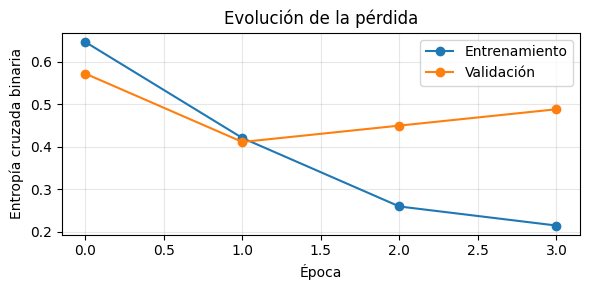

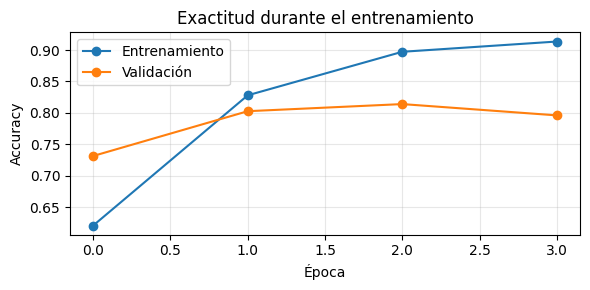

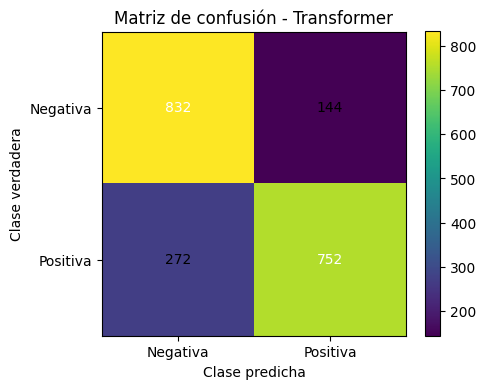

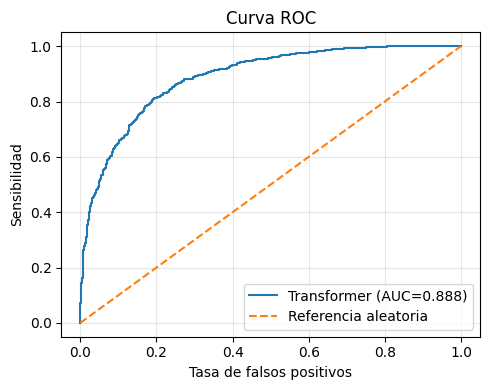

In [3]:

# Gráfica 1: evolución de la pérdida
plt.figure(figsize=(6, 3))
plt.plot(historia.history["loss"], "o-", label="Entrenamiento")
plt.plot(historia.history["val_loss"], "o-", label="Validación")
plt.xlabel("Época")
plt.ylabel("Entropía cruzada binaria")
plt.title("Evolución de la pérdida")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfica 2: evolución de la exactitud
plt.figure(figsize=(6, 3))
plt.plot(historia.history["accuracy"], "o-", label="Entrenamiento")
plt.plot(historia.history["val_accuracy"], "o-", label="Validación")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Exactitud durante el entrenamiento")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfica 3: matriz de confusión
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.xticks([0, 1], ["Negativa", "Positiva"])
plt.yticks([0, 1], ["Negativa", "Positiva"])
plt.xlabel("Clase predicha")
plt.ylabel("Clase verdadera")
plt.title("Matriz de confusión - Transformer")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center",
                 color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
plt.show()

# Gráfica 4: curva ROC
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_te, prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"Transformer (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Referencia aleatoria")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Sensibilidad")
plt.title("Curva ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:

import os
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)

# Reproducibilidad
keras.utils.set_random_seed(42)
rng = np.random.default_rng(42)

# Parámetros
VOCAB = 8000
MAX_LEN = 120
EMBED_DIM = 32
BATCH = 128
EPOCHS = 5

# Cargar IMDB (utiliza la copia local si ya fue descargada)
try:
    (x_train_all, y_train_all), (x_test_all, y_test_all) = (
        keras.datasets.imdb.load_data(num_words=VOCAB)
    )
except Exception as e:
    raise RuntimeError(
        "No se pudo cargar IMDB. Si no tienes Internet, "
        "verifica que imdb.npz esté guardado en la caché de Keras."
    ) from e

# Separar entrenamiento, validación y prueba
idx = rng.permutation(len(x_train_all))

it = idx[:6000]
iv = idx[6000:7500]
ie = rng.permutation(len(x_test_all))[:2000]

def preparar(secuencias, indices):
    return keras.utils.pad_sequences(
        [secuencias[i] for i in indices],
        maxlen=MAX_LEN,
        padding="post",
        truncating="post",
        value=0
    ).astype("int32")

X_tr = preparar(x_train_all, it)
X_va = preparar(x_train_all, iv)
X_te = preparar(x_test_all, ie)

y_tr = np.asarray(y_train_all)[it]
y_va = np.asarray(y_train_all)[iv]
y_te = np.asarray(y_test_all)[ie]

print("Entrenamiento:", X_tr.shape)
print("Validación   :", X_va.shape)
print("Prueba       :", X_te.shape)
print("Clases en prueba:", np.bincount(y_te))



Entrenamiento: (6000, 120)
Validación   : (1500, 120)
Prueba       : (2000, 120)
Clases en prueba: [ 976 1024]



### **Interpretación de la evaluación del Transformer**

**1. Pérdida de entrenamiento y validación.** Permite identificar si el modelo está aprendiendo. Una disminución de ambas pérdidas indica una mejora del objetivo de entrenamiento. Si la pérdida de entrenamiento disminuye mientras la de validación aumenta, puede existir **sobreajuste**.

**2. Matriz de confusión.** Permite identificar cuatro resultados: verdaderos positivos ($VP$), verdaderos negativos ($VN$), falsos positivos ($FP$) y falsos negativos ($FN$). A partir de ellos calculamos:

$$
\begin{aligned}
\text{Accuracy}&=\frac{VP+VN}{VP+VN+FP+FN},\\
\text{Precision}&=\frac{VP}{VP+FP},\\
\text{Recall}&=\frac{VP}{VP+FN},\\
\text{Especificidad}&=\frac{VN}{VN+FP},\\
F_1&=2\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}.
\end{aligned}
$$

**3. Curva ROC y AUC.** La curva ROC relaciona la sensibilidad con la tasa de falsos positivos para diferentes umbrales. Un AUC cercano a $1$ indica una excelente capacidad de discriminación; un valor cercano a $0.5$ corresponde a una discriminación comparable al azar.

**4. Evaluación individual.** Comparar la etiqueta verdadera, la probabilidad estimada y la clase predicha permite comprender por qué una reseña fue clasificada correctamente o incorrectamente.

**Conclusión.** El desempeño del Transformer debe evaluarse con datos independientes del entrenamiento. No basta con observar que la pérdida disminuye: es necesario analizar la capacidad de generalización mediante métricas de clasificación, la matriz de confusión y los errores individuales.


In [2]:
# ==== Configuración global (ejecutar primero) ====
import math, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
print("TensorFlow:", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

def softmax_np(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True); e = np.exp(x); return e / e.sum(axis=axis, keepdims=True)

I0000 00:00:1795150562.436802  372268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795150562.846072  372268 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795150565.381351  372268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | GPU: False


W0000 00:00:1795150568.452400  372268 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


**Teacher forcing frente a estrategia de decodificación**

En la fórmula para $y_t$ de tu texto las etiquetas aparecen **intercambiadas**. Lo correcto es:

- **Entrenamiento (*teacher forcing*):** el decoder recibe como entrada el token **real** $y_{t-1}^{\text{real}}$ y se minimiza $-\sum_t\log p_\theta(y_t^{\text{real}}\mid y_{<t}^{\text{real}},X)$. **No se muestrea nada.**
- **Inferencia:** el decoder recibe su **propia** salida previa, y el siguiente token se elige con una *estrategia de decodificación*:

$$
y_t=\begin{cases}
\arg\max_{v}\, p_\theta(v\mid y_{<t},X) & \text{(voraz / greedy)}\\[2pt]
y\sim p_\theta(\cdot\mid y_{<t},X) & \text{(muestreo)}\\[2pt]
\text{top-}k,\ \text{top-}p,\ \text{beam search} & \text{(variantes)}
\end{cases}
$$

La discrepancia entre entrenar con tokens reales y generar con tokens propios se llama **sesgo de exposición** (*exposure bias*) [Ranzato et al., 2016].

**Precisión: el «Teorema (Yun et al., 2020)»**

La frase *«Multi-head attention puede aproximar cualquier función continua de múltiples variables»* es **imprecisa**. El resultado correcto se enuncia en el **Teorema 9** (Bloque H): se trata de **Transformers completos** (atención **más** capas feed-forward), de funciones **secuencia-a-secuencia** continuas sobre un **dominio compacto**, con aproximación en norma $L^p$ ($1\le p<\infty$), y la clase aproximada es la de funciones **equivariantes a permutación**, salvo que se añada **codificación posicional**. Una capa de atención *sola* no es un aproximador universal.

**Precisión: «sin desvanecimiento del gradiente» requiere matices**

La tabla afirma que en el Transformer el gradiente es «$O(1)$» y «sin desvanecimiento». Es una **simplificación imprecisa**:

1. La residual garantiza un **término identidad** en el jacobiano, $\partial y/\partial x=I+\partial F/\partial x$, pero a través de $L$ capas el gradiente es un **producto** $\prod_l(I+J_l)$ cuya norma puede **crecer o decrecer**.
2. La **posición de LayerNorm importa**: en la arquitectura original (**Post-LN**) los gradientes cerca de la salida son grandes en la inicialización y exigen *warm-up*; en **Pre-LN** están mejor condicionados (**T6**, Bloque E) [Xiong et al., 2020].
3. La autoatención *pura* sufre **colapso de rango doblemente exponencial** con la profundidad (**T5**) [Dong et al., 2021]; las residuales son precisamente lo que lo evita.

Un enunciado correcto: *la autoatención conecta cualquier par de tokens con un camino de longitud 1 (frente a $O(n)$ en una RNN) y las residuales preservan un camino directo para el gradiente; pero la estabilidad real depende de la normalización y la inicialización.*


## **A. Atención clásica en TensorFlow**
Implementamos las dos puntuaciones de alineamiento como capas de Keras y verificamos que producen distribuciones válidas.

In [3]:
class BahdanauAttention(layers.Layer):
    # e_tj = v_a^T tanh(W_a s + U_a h_j)   (aditiva)
    def __init__(self, units, **kw):
        super().__init__(**kw)
        self.Wa = layers.Dense(units, use_bias=False); self.Ua = layers.Dense(units, use_bias=False); self.va = layers.Dense(1, use_bias=False)
    def call(self, s, H):                                   # s: (B,d_s)  H: (B,S,d_h)
        e = self.va(tf.tanh(self.Wa(s)[:, None, :] + self.Ua(H)))
        alpha = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(alpha * H, axis=1), tf.squeeze(alpha, -1)

class LuongAttention(layers.Layer):
    # e_tj = s^T W_a h_j   (multiplicativa "general")
    def __init__(self, d_h, **kw):
        super().__init__(**kw); self.Wa = layers.Dense(d_h, use_bias=False)
    def call(self, s, H):
        e = tf.einsum("bd,bsd->bs", self.Wa(s), H); alpha = tf.nn.softmax(e, axis=-1)
        return tf.einsum("bs,bsd->bd", alpha, H), alpha

B, S, dh, ds = 2, 4, 16, 16
H = tf.random.normal((B, S, dh)); s = tf.random.normal((B, ds))
for name, layer in [("Bahdanau", BahdanauAttention(32)), ("Luong", LuongAttention(dh))]:
    c, a = layer(s, H)
    print(f"{name:9s} contexto {c.shape} | pesos suman 1: {np.allclose(a.numpy().sum(-1), 1.0, atol=1e-5)} | min >= 0: {a.numpy().min() >= 0}")

Bahdanau  contexto (2, 16) | pesos suman 1: True | min >= 0: True
Luong     contexto (2, 16) | pesos suman 1: True | min >= 0: True



## **B. Propiedades matemáticas de la autoatención**
**Notación.** $X\in\mathbb{R}^{n\times d}$ (una fila por token), $Q=XW_Q,\ K=XW_K,\ V=XW_V$ y
$$\operatorname{Attn}(X)=\operatorname{softmax}\!\Big(\tfrac{QK^\top}{\sqrt{d_k}}+M\Big)V,$$
con $M$ una máscara aditiva ($M=0$ sin máscara; $M_{ij}=-\infty$ si $j>i$ en el caso causal).

### **Teorema 1 (Equivarianza a permutaciones)**
> **Teorema 1.** Sea $\boldsymbol{P}$ una matriz de permutación y $M=0$. Entonces para cualesquiera $W_Q,W_K,W_V$,
> $$\operatorname{Attn}(\boldsymbol{P}X)=\boldsymbol{P}\,\operatorname{Attn}(X).$$
> La autoatención (y multi-head, residuales, LayerNorm y FFN por token) es **equivariante a permutaciones**. En consecuencia, **sin información posicional un Transformer sólo ve un multiconjunto de tokens**.
>
> **Corolario.** Si $x_i=x_j$, las filas $i,j$ de la salida son iguales. Con **máscara causal** el resultado **falla**: la máscara rompe la simetría y *codifica implícitamente* el orden.


#### **Demostración**
**¿Qué queremos demostrar?** Que si cambiamos el orden de los tokens de entrada, las salidas cambian en el mismo orden, siempre que no exista información posicional ni máscara. **Estrategia:** seguir el efecto de la permutación en $Q$, $K$, $V$, *softmax* y la salida.

**Paso 1 · Permutar filas.** Sea $P\in\mathbb R^{n\times n}$ una matriz de permutación: cada fila y columna tiene un solo $1$, y $P^\top P=I$. Cambiar el orden de entrada equivale a $X'=PX$.

**Paso 2 · Proyectar.** Puesto que los mismos pesos actúan sobre cada token, $(PX)W_Q=P(XW_Q)=PQ$. De forma análoga, $K'=PK$ y $V'=PV$.

**Paso 3 · Calcular similitudes.** $S'=Q'K'^\top/\sqrt{d_k}=(PQ)(PK)^\top/\sqrt{d_k}=P(QK^\top/\sqrt{d_k})P^\top=PSP^\top$.

**Paso 4 · Aplicar softmax.** Para una fila $i$, $\operatorname{softmax}(s_i)_j=e^{s_{ij}}/\sum_{k=1}^n e^{s_{ik}}$. Reordenar sus columnas no cambia el denominador (sigue siendo la misma suma); reordenar filas solo cambia qué fila aparece primero. Por tanto,
$$\operatorname{softmax}(PSP^\top)=P\operatorname{softmax}(S)P^\top.$$

**Paso 5 · Multiplicar por los valores.** Como $P^\top P=I$:
$$\begin{aligned}\operatorname{Attn}(PX)&=\operatorname{softmax}(PSP^\top)(PV)\\&=P\operatorname{softmax}(S)\underbrace{P^\top P}_{I}V\\&=P\operatorname{Attn}(X).\end{aligned}$$


**Conclusión:** la salida cambia de orden de la misma forma que la entrada: esto se denomina **equivarianza**, no invariancia. **Excepción:** la máscara causal fija una relación de precedencia y, en general, no satisface $PMP^\top=M$. $\blacksquare$

In [4]:
# ---- Verificación del Teorema 1 ----
def attn_tf(X, WQ, WK, WV, mask=None):
    Q, K, V = X @ WQ, X @ WK, X @ WV
    S = Q @ tf.transpose(K) / math.sqrt(WK.shape[-1])
    if mask is not None: S = S + mask
    return tf.nn.softmax(S, axis=-1) @ V

n, d, dk = 7, 16, 8
X  = tf.random.normal((n, d)); WQ, WK, WV = [tf.random.normal((d, dk)) / math.sqrt(d) for _ in range(3)]
P = tf.one_hot(tf.random.shuffle(tf.range(n)), n)
Y, Yp = attn_tf(X, WQ, WK, WV), attn_tf(P @ X, WQ, WK, WV)
print(f"sin máscara : ||Attn(PX) - P Attn(X)|| = {tf.norm(Yp - P @ Y).numpy():.2e}   (≈ 0)")
M = tf.constant(np.triu(np.full((n, n), -1e9, dtype="float32"), 1))
print(f"causal      : ||Attn(PX) - P Attn(X)|| = {tf.norm(attn_tf(P @ X, WQ, WK, WV, M) - P @ attn_tf(X, WQ, WK, WV, M)).numpy():.2e}   (> 0)")
Xi = tf.tile(tf.random.normal((1, d)), (n, 1)); Yi = attn_tf(Xi, WQ, WK, WV)
print("tokens idénticos -> filas idénticas:", np.allclose(Yi.numpy(), Yi.numpy()[0], atol=1e-5))

sin máscara : ||Attn(PX) - P Attn(X)|| = 4.73e-07   (≈ 0)
causal      : ||Attn(PX) - P Attn(X)|| = 4.28e+00   (> 0)
tokens idénticos -> filas idénticas: True


### **Teorema 2 (Escalado $1/\sqrt{d_k}$: varianza y saturación de la softmax)**

> **Teorema 2.** Sean $q,k\in\mathbb{R}^{d_k}$ con componentes **independientes**, media $0$ y varianza $1$. Entonces
> $$\mathbb{E}[q^\top k]=0,\qquad \operatorname{Var}(q^\top k)=d_k,\qquad \operatorname{Var}\!\Big(\tfrac{q^\top k}{\sqrt{d_k}}\Big)=1.$$
> Además, si los scores tienen desviación típica $\sigma_s\to\infty$, la softmax tiende a un vector *one-hot* y su jacobiano $J=\operatorname{diag}(p)-pp^\top$ tiende a $0$: **los gradientes se anulan**.


#### **Demostración guiada**
**¿Qué queremos demostrar?** Por qué se divide el producto $q^\top k$ por $\sqrt{d_k}$: buscamos impedir que su varianza aumente con la dimensión y comprender su relación con la saturación de *softmax*.

**Paso 1 · Expanda el producto escalar:** $s=q^\top k=\sum_{i=1}^{d_k}q_i k_i$. Suponga componentes centradas, de varianza unitaria, e independencia suficiente entre los productos $q_i k_i$.

**Paso 2 · Calcule la esperanza.** Por independencia entre $q_i$ y $k_i$, $\mathbb E[q_i k_i]=\mathbb E[q_i]\mathbb E[k_i]=0$. Por linealidad, $\mathbb E[s]=\sum_i0=0$.

**Paso 3 · Calcule la varianza de un término.** Como la media es cero,
$$\operatorname{Var}(q_i k_i)=\mathbb E[q_i^2k_i^2]=\mathbb E[q_i^2]\mathbb E[k_i^2]=1\cdot1=1.$$
**Paso 4 · Sume varianzas.** Bajo independencia entre términos, $\operatorname{Var}(s)=\sum_{i=1}^{d_k}1=d_k$, de modo que su desviación típica es $\sqrt{d_k}$. **Por ejemplo:** si $d_k=64$, la varianza es $64$ y la desviación típica es $8$.

**Paso 5 · Normalice.** Para constante $c$, $\operatorname{Var}(cs)=c^2\operatorname{Var}(s)$; por tanto,
$$\operatorname{Var}\!\left(\frac{s}{\sqrt{d_k}}\right)=\frac{1}{d_k}\cdot d_k=1.$$

**Paso 6 · Relacione con el gradiente.** Para $p_i=e^{s_i}/\sum_je^{s_j}$, derive mediante la regla del cociente:
$$\frac{\partial p_i}{\partial s_j}=p_i(\delta_{ij}-p_j),\qquad J=\operatorname{diag}(p)-pp^\top.$$
Si hay una puntuación claramente máxima y la escala tiende a infinito, $p\to(1,0,\ldots,0)$ (salvo empates); entonces todos los términos del jacobiano tienden a cero. **El escalado reduce la saturación típica en la inicialización**, pero no garantiza gradientes no nulos en cualquier entrenamiento. $\blacksquare$

In [5]:
# ---- Verificación del Teorema 2 ----
rng = np.random.default_rng(0)
print(f"{'d_k':>6} {'Var(q·k)':>10} {'teoría':>8} {'Var(q·k/√dk)':>14} | {'H sin esc.':>10} {'H con esc.':>10} | {'||J|| sin':>9} {'||J|| con':>9}")
for dk_ in [4, 16, 64, 256, 1024]:
    q = rng.normal(size=(20000, dk_)); k = rng.normal(size=(20000, dk_)); dots = (q * k).sum(1)
    qq = rng.normal(size=(300, dk_)); KK = rng.normal(size=(64, dk_))
    s_un = qq @ KK.T; s_sc = s_un / np.sqrt(dk_); p_un, p_sc = softmax_np(s_un), softmax_np(s_sc)
    H  = lambda p: float((-(p * np.log(p + 1e-30)).sum(-1)).mean())
    Jn = lambda p: float(np.mean([np.linalg.norm(np.diag(r) - np.outer(r, r)) for r in p]))
    print(f"{dk_:6d} {dots.var():10.1f} {dk_:8d} {(dots/np.sqrt(dk_)).var():14.3f} | {H(p_un):10.3f} {H(p_sc):10.3f} | {Jn(p_un):9.4f} {Jn(p_sc):9.4f}")
print(f"(entropía máxima con 64 claves = {np.log(64):.3f})")

   d_k   Var(q·k)   teoría   Var(q·k/√dk) | H sin esc. H con esc. | ||J|| sin ||J|| con
     4        4.0        4          1.001 |      2.604      3.661 |    0.2650    0.1868
    16       16.1       16          1.005 |      1.328      3.672 |    0.2801    0.1847
    64       64.1       64          1.001 |      0.637      3.710 |    0.2276    0.1801
   256      256.4      256          1.002 |      0.269      3.678 |    0.1274    0.1843
  1024     1020.6     1024          0.997 |      0.126      3.690 |    0.0669    0.1828
(entropía máxima con 64 claves = 4.159)


### **Teorema 3 (Rango de la matriz de scores)** 
> **Teorema 3.** Sea $S=\tfrac1{\sqrt{d_k}}XW_QW_K^\top X^\top\in\mathbb{R}^{n\times n}$. Entonces $\operatorname{rank}(S)\le d_k$. Recíprocamente, si $d_k\ge n$, $d\ge n$ y $X$ tiene rango fila completo, **toda** matriz estocástica por filas con entradas positivas $A$ es representable como $A=\operatorname{softmax}(S)$ para algún $S$ de esa forma. Con $d_k<n$ sólo se representan aproximaciones de bajo rango en el espacio de *logits*.


#### **Demostración**

**¿Qué queremos demostrar?** Primero, que el rango de la matriz de similitudes antes de *softmax* no supera $d_k$. Después, que con dimensión suficiente pueden construirse pesos de atención positivos deseados.

**Paso 1 · Identifique los factores.** Como $Q=XW_Q\in\mathbb R^{n\times d_k}$ y $K=XW_K\in\mathbb R^{n\times d_k}$, se tiene $S=QK^\top/\sqrt{d_k}$.

**Paso 2 · Utilice la desigualdad de rango.** Para matrices compatibles $A,B$, $\operatorname{rank}(AB)\le\min\{\operatorname{rank}(A),\operatorname{rank}(B)\}$. En consecuencia,
$$\operatorname{rank}(S)\le\min\{\operatorname{rank}(Q),\operatorname{rank}(K)\}\le d_k.$$

**Paso 3 · Pregunte qué matriz de scores produce pesos dados.** Para una matriz $A$ con $A_{ij}>0$ y $\sum_j A_{ij}=1$, escriba $S^*=\log A$ **elemento a elemento**. Así $\operatorname{softmax}(S^*)_{ij}=A_{ij}/\sum_j A_{ij}=A_{ij}$.

**Paso 4 · Reconstruya los scores cuando $X$ tiene rango fila completo.** La pseudoinversa satisface $XX^+=I_n$. Ponga $B=\sqrt{d_k}\,X^+S^*(X^\top)^+$. Entonces,
$$\frac{1}{\sqrt{d_k}}XBX^\top=XX^+S^*(X^\top)^+X^\top=S^*.$$

**Paso 5 · Factorice.** $B$ es una matriz $d\times d$ con rango a lo sumo $n\le d_k$; cualquier matriz de rango $r\le d_k$ admite factorización $B=W_QW_K^\top$ con $W_Q,W_K\in\mathbb R^{d\times d_k}$ (por SVD y completando columnas nulas). Así $\operatorname{softmax}(S)=A$.

**Precisión:** la cota de rango afecta a **$S$ antes de softmax**, no implica que $\operatorname{rank}(\operatorname{softmax}(S))\le d_k$. $\blacksquare$

(a) softmax(S) == A con la construcción: True | rank(W) = 8 <= n = 8


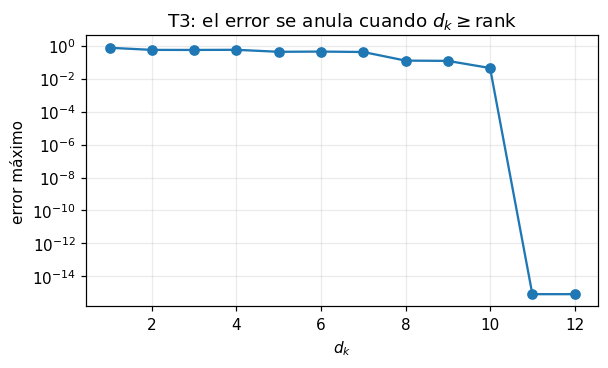

In [6]:
# ---- Verificación del Teorema 3: (a) la construcción, (b) el error al limitar d_k ----
rng = np.random.default_rng(2); n, d, dk = 8, 16, 8
X_ = rng.normal(size=(n, d)); A_ = softmax_np(rng.normal(size=(n, n)) * 2); Sstar = np.log(A_)
Xp = np.linalg.pinv(X_); W = np.sqrt(dk) * Xp @ Sstar @ Xp.T
print("(a) softmax(S) == A con la construcción:", np.allclose(softmax_np(X_ @ W @ X_.T / np.sqrt(dk)), A_), "| rank(W) =", np.linalg.matrix_rank(W), "<= n =", n)

rng = np.random.default_rng(1); n = 12
target = softmax_np(rng.normal(size=(n, n)) * 2); logT = np.log(target); logT -= logT.mean(1, keepdims=True)
U, s, Vt = np.linalg.svd(logT); errs = []
for dk_ in range(1, n + 1):
    Sk = (U[:, :dk_] * s[:dk_]) @ Vt[:dk_]; errs.append(np.abs(softmax_np(Sk) - target).max())
plt.figure(figsize=(6, 3.2)); plt.semilogy(range(1, n + 1), np.maximum(errs, 1e-17), "o-")
plt.xlabel("$d_k$"); plt.ylabel("error máximo"); plt.title("T3: el error se anula cuando $d_k \\geq \\mathrm{rank}$"); plt.show()


## **C. Codificación posicional**
Por el Teorema 1 hay que inyectar el orden.

| Método | Idea | Dónde | Ref. |
|---|---|---|---|
| **Sinusoidal** | $PE_{p,2i}=\sin(p/10000^{2i/d}),\ PE_{p,2i+1}=\cos(\cdot)$ sumada al embedding | entrada | [1] |
| **Aprendida** | tabla de $n_{\max}$ vectores entrenables | entrada | [8] |
| **Relativa (Shaw)** | sesgos que dependen de $j-i$ | dentro de la atención | [9] |
| **RoPE** | rota $q,k$ por un ángulo proporcional a la posición | sobre $q,k$ | [10] |
| **ALiBi** | sesgo lineal $-m|i-j|$ sobre los scores | scores | [11] |

**Propiedad deseable:** que $q_m^\top k_n$ dependa de las posiciones sólo por $m-n$. La sinusoidal **aditiva** no la cumple exactamente (aparecen términos cruzados); RoPE sí.


### **Teorema 4 (Propiedad relativa de RoPE)**

**Teorema 4.** Sea $d$ par, $\theta_i=b^{-2(i-1)/d}$, con $b=10000$, y definamos:

$$
R_m=\operatorname{blockdiag}\left(R(m\theta_1),\ldots,R(m\theta_{d/2})\right),
\qquad
R(\varphi)=
\begin{pmatrix}
\cos\varphi & -\sin\varphi\\
\sin\varphi & \cos\varphi
\end{pmatrix}.
$$

Si $\tilde{\boldsymbol{q}}_m=R_m\boldsymbol{q}$ y $\tilde{\boldsymbol{k}}_n=R_n\boldsymbol{k}$, entonces:

$$
\boxed{
\tilde{\boldsymbol{q}}_m^T\tilde{\boldsymbol{k}}_n
=\boldsymbol{q}^TR_{n-m}\boldsymbol{k},
\qquad
R_m^TR_n=R_{n-m}
}
$$

Por tanto, para $\boldsymbol{q}$ y $\boldsymbol{k}$ fijos, el **score depende de las posiciones únicamente mediante la diferencia $n-m$**. Además, como $R_m$ es ortogonal:

$$
\boxed{
\|\tilde{\boldsymbol{q}}_m\|_2=\|\boldsymbol{q}\|_2
}
$$




#### **Demostración**
**¿Qué queremos demostrar?** Que rotar consultas y claves según su posición convierte la similitud en una expresión dependiente del desplazamiento relativo $n-m$, y que la rotación no altera las normas.

**Paso 1 · Escriba las rotaciones.** En dos dimensiones, $R(\varphi)=\begin{pmatrix}\cos\varphi&-\sin\varphi\\\sin\varphi&\cos\varphi\end{pmatrix}$.

**Paso 2 · Compruebe las identidades.** Las identidades trigonométricas implican $R(\alpha)^\top=R(-\alpha)$ y $R(\alpha)R(\beta)=R(\alpha+\beta)$; de ahí $R(\alpha)^\top R(\beta)=R(\beta-\alpha)$.

**Paso 3 · Extienda a cada par de coordenadas.** $R_m$ es diagonal por bloques, con ángulo $m\theta_i$ en el par $i$. Al multiplicar $R_m^\top R_n$, cada bloque es $R(-m\theta_i)R(n\theta_i)=R((n-m)\theta_i)$; por ello $R_m^\top R_n=R_{n-m}$.

**Paso 4 · Reemplace en el score.** Si $\widetilde q_m=R_mq$ y $\widetilde k_n=R_nk$,
$$\widetilde q_m^\top\widetilde k_n=q^\top R_m^\top R_nk=q^\top R_{n-m}k.$$

**Paso 5 · Compruebe norma constante.** Como $R_m^\top R_m=I$, $\|R_mq\|_2^2=q^\top R_m^\top R_mq=\|q\|_2^2$.

**Ejemplo:** si $m=3$, $n=8$, la dependencia posicional está en $n-m=5$ y no en las posiciones absolutas tomadas por separado (para $q,k$ fijos). **Eso no garantiza por sí solo extrapolación perfecta a cualquier longitud.** $\blacksquare$

máx. desviación dentro de cada diagonal (n-m fijo): 3.34e-06   (≈ 0 ⇒ sólo importa n-m)
isometría: ||R q|| = 4.148362  vs  ||q|| = 4.148362
sinusoidal aditiva: máx. desviación por diagonal = 6.3780  |  RoPE: 3.34e-06


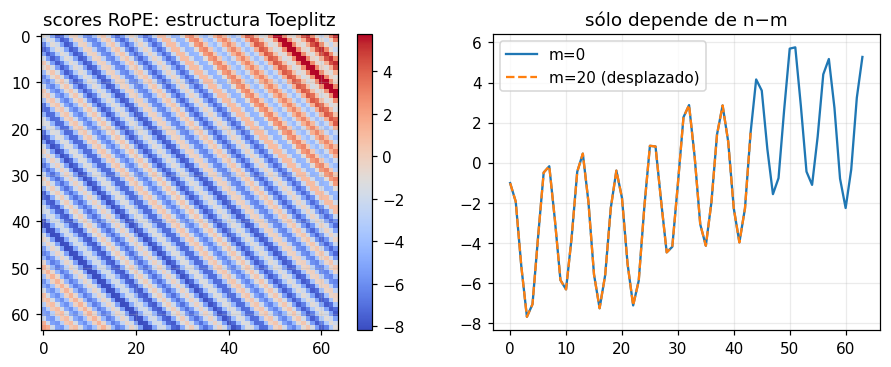

In [7]:
# ---- RoPE en TF (longitud dinámica) y verificación del Teorema 4 ----
def rope_angles(n, d, base=10000.0):
    theta = tf.constant(base ** (-np.arange(0, d, 2) / d), dtype=tf.float32)
    ang = tf.einsum("n,k->nk", tf.cast(tf.range(n), tf.float32), theta)
    return tf.cos(ang), tf.sin(ang)

def apply_rope(x, cos, sin):                                         # x: (..., n, d)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    r1, r2 = x1 * cos - x2 * sin, x1 * sin + x2 * cos
    return tf.reshape(tf.stack([r1, r2], axis=-1), tf.shape(x))

d, n = 16, 64
cos, sin = rope_angles(n, d)
q, k = tf.random.normal((d,)), tf.random.normal((d,))
Q = apply_rope(tf.tile(q[None], (n, 1)), cos, sin); K = apply_rope(tf.tile(k[None], (n, 1)), cos, sin)
scores = (Q @ tf.transpose(K)).numpy()
max_dev = max(np.ptp(np.diagonal(scores, offset=o)) for o in range(-n + 1, n))
print(f"máx. desviación dentro de cada diagonal (n-m fijo): {max_dev:.2e}   (≈ 0 ⇒ sólo importa n-m)")
print(f"isometría: ||R q|| = {tf.norm(Q[37]).numpy():.6f}  vs  ||q|| = {tf.norm(q).numpy():.6f}")

# Comparación con la sinusoidal ADITIVA
def sinusoidal(n, d):
    pos = np.arange(n)[:, None]; i = np.arange(d // 2)[None]; ang = pos / (10000 ** (2 * i / d)); pe = np.zeros((n, d), "float32")
    pe[:, 0::2], pe[:, 1::2] = np.sin(ang), np.cos(ang); return pe
dm, dk_, nn = 32, 16, 40; pe = sinusoidal(nn, dm); WQ_, WK_ = np.random.randn(dm, dk_) / 6, np.random.randn(dm, dk_) / 6
xx = np.random.randn(dm); sc_add = ((xx + pe) @ WQ_) @ ((xx + pe) @ WK_).T
dev_add = max(np.ptp(np.diagonal(sc_add, offset=o)) for o in range(-nn + 1, nn) if abs(o) < nn - 2)
print(f"sinusoidal aditiva: máx. desviación por diagonal = {dev_add:.4f}  |  RoPE: {max_dev:.2e}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5)); im = ax[0].imshow(scores, cmap="coolwarm"); ax[0].set_title("scores RoPE: estructura Toeplitz"); plt.colorbar(im, ax=ax[0])
ax[1].plot(scores[0], label="m=0"); ax[1].plot(scores[20, 20:], "--", label="m=20 (desplazado)"); ax[1].legend(); ax[1].set_title("sólo depende de n−m"); plt.show()

### **Mapa Transformer**

| **Operación** | **Cálculo** | **Dimensión de salida** |
|:--|:--|:--|
| **Proyectar** | $Q=XW_Q$, $K=XW_K$, $V=XW_V$ | $n\times d_k$, $n\times d_k$, $n\times d_v$ |
| **Atender** | $A=\operatorname{softmax}(QK^\top/\sqrt{d_k}+M)$ | $n\times n$ |
| **Combinar** | $Z=AV$ | $n\times d_v$ |
| **Concatenar cabezas** | $H=\operatorname{Concat}(Z_1,\ldots,Z_h)W_O$ | $n\times d_{\mathrm{model}}$ |
| **Residual y FFN** | $Y=\operatorname{Norm}(X+H)$; $Y'=\operatorname{Norm}(Y+\mathrm{FFN}(Y))$ | $n\times d_{\mathrm{model}}$ |

**¿Por qué múltiples cabezas?** Cada cabeza aprende **proyecciones diferentes** y puede atender a relaciones distintas. **Importante:** la forma de la normalización anterior corresponde a **Post-LN**; la variante **Pre-LN** normaliza antes de cada subcapa.



## **D. El bloque Transformer completo en TensorFlow**
Implementamos **desde cero** atención con máscara, multi-head (con **GQA**), FFN, residuales, LayerNorm y los dos órdenes de normalización:
$$\text{Post-LN: } x\mapsto \mathrm{LN}\big(x+F(x)\big)\qquad\qquad \text{Pre-LN: } x\mapsto x+F\big(\mathrm{LN}(x)\big).$$

In [8]:
# Ejemplo ejecutable: ejecute luego de leer las dimensiones y el enunciado anterior.
class MultiHeadAttention(layers.Layer):
    # Multi-cabeza propia con soporte GQA (n_kv_heads < n_heads), máscara causal, cross-attention y RoPE opcional.
    def __init__(self, d_model, n_heads, n_kv_heads=None, causal=False, rope=False, **kw):
        super().__init__(**kw)
        assert d_model % n_heads == 0
        self.h, self.hk = n_heads, (n_kv_heads or n_heads)
        assert self.h % self.hk == 0, "n_heads debe ser múltiplo de n_kv_heads"
        self.dh, self.causal, self.rope = d_model // n_heads, causal, rope
        self.wq = layers.Dense(self.h  * self.dh, use_bias=False)
        self.wk = layers.Dense(self.hk * self.dh, use_bias=False)
        self.wv = layers.Dense(self.hk * self.dh, use_bias=False)
        self.wo = layers.Dense(d_model, use_bias=False)

    def _split(self, x, h):                                   # (B,n,h*dh) -> (B,h,n,dh)
        B, n = tf.shape(x)[0], tf.shape(x)[1]
        return tf.transpose(tf.reshape(x, (B, n, h, self.dh)), (0, 2, 1, 3))

    def call(self, x, context=None, return_weights=False):
        ctx = x if context is None else context
        q, k, v = self._split(self.wq(x), self.h), self._split(self.wk(ctx), self.hk), self._split(self.wv(ctx), self.hk)
        if self.rope:
            cos, sin = rope_angles(tf.shape(q)[2], self.dh)   # longitud dinámica (robusto en tf.function)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        rep = self.h // self.hk
        if rep > 1: k, v = tf.repeat(k, rep, axis=1), tf.repeat(v, rep, axis=1)
        s = tf.matmul(q, k, transpose_b=True) / math.sqrt(self.dh)
        if self.causal:
            nq, nk = tf.shape(s)[-2], tf.shape(s)[-1]
            s += (1.0 - tf.linalg.band_part(tf.ones((nq, nk)), -1, 0)) * -1e9
        a = tf.nn.softmax(s, axis=-1)
        o = tf.matmul(a, v)
        o = tf.reshape(tf.transpose(o, (0, 2, 1, 3)), (tf.shape(x)[0], tf.shape(x)[1], self.h * self.dh))
        o = self.wo(o)
        return (o, a) if return_weights else o


class TransformerBlock(layers.Layer):
    def __init__(self, d_model, n_heads, d_ff, n_kv_heads=None, causal=False, rope=False,
                 pre_ln=True, dropout=0.1, cross=False, **kw):
        super().__init__(**kw)
        self.pre_ln, self.cross = pre_ln, cross
        self.attn = MultiHeadAttention(d_model, n_heads, n_kv_heads, causal, rope)
        self.xattn = MultiHeadAttention(d_model, n_heads) if cross else None
        self.ffn = keras.Sequential([layers.Dense(d_ff, activation="gelu"), layers.Dense(d_model)])
        self.ln1, self.ln2, self.ln3 = [layers.LayerNormalization(epsilon=1e-6) for _ in range(3)]
        self.drop = layers.Dropout(dropout)

    def call(self, x, context=None, training=False):
        if self.pre_ln:                                        # x + F(LN(x))
            x = x + self.drop(self.attn(self.ln1(x)), training=training)
            if self.cross: x = x + self.drop(self.xattn(self.ln3(x), context=context), training=training)
            x = x + self.drop(self.ffn(self.ln2(x)), training=training)
        else:                                                  # LN(x + F(x))
            x = self.ln1(x + self.drop(self.attn(x), training=training))
            if self.cross: x = self.ln3(x + self.drop(self.xattn(x, context=context), training=training))
            x = self.ln2(x + self.drop(self.ffn(x), training=training))
        return x

blk = TransformerBlock(64, 8, 256, n_kv_heads=2, causal=True, rope=True)
print("salida:", blk(tf.random.normal((2, 10, 64))).shape, "| parámetros:", blk.count_params())

salida: (2, 10, 64) | parámetros: 43584


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [9]:
# ---- Verificaciones de corrección ----
mha = MultiHeadAttention(64, 8, causal=True); x = tf.random.normal((1, 12, 64)); o, a = mha(x, return_weights=True); a = a.numpy()
print("pesos suman 1 por fila:", np.allclose(a.sum(-1), 1.0, atol=1e-5))
print("causalidad (nada sobre la diagonal):", np.abs(np.triu(a[0, 0], 1)).max() < 1e-6)
x2 = x.numpy().copy(); x2[:, 8:] = np.random.randn(1, 4, 64); o2 = mha(tf.constant(x2))
print("posiciones 0..7 invariantes a cambios futuros:", np.allclose(o.numpy()[:, :8], o2.numpy()[:, :8], atol=1e-5))
for hk in [8, 4, 2, 1]:
    m = MultiHeadAttention(64, 8, n_kv_heads=hk); _ = m(x); print(f"n_kv_heads={hk}: parámetros = {m.count_params()}")

pesos suman 1 por fila: True
causalidad (nada sobre la diagonal): True
posiciones 0..7 invariantes a cambios futuros: True
n_kv_heads=8: parámetros = 16384
n_kv_heads=4: parámetros = 12288
n_kv_heads=2: parámetros = 10240
n_kv_heads=1: parámetros = 9216


### **Un modelo de lenguaje a nivel de caracteres (decoder-only)**
Un **Transformer decoder-only** (como GPT) con RoPE y Pre-LN. Aquí se ve el **teacher forcing**: la entrada es la secuencia real y el objetivo es esa misma secuencia **desplazada una posición**.

In [10]:
# ---- Datos: texto sintético con gramática simple ----
subj = ["el gato", "la niña", "un perro", "el profesor", "la estudiante"]; verb = ["duerme", "come", "estudia", "corre", "lee"]; adv = ["rápido", "despacio", "mucho", "poco", "bien"]
rng = np.random.default_rng(0)
text = " . ".join(f"{rng.choice(subj)} {rng.choice(verb)} {rng.choice(adv)}" for _ in range(1500)) + " ."
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
data = np.array([stoi[c] for c in text], dtype="int32"); V = len(chars); ctx = 48
def make_ds(arr, ctx, bs=128):
    xs = np.stack([arr[i:i + ctx] for i in range(0, len(arr) - ctx - 1, 3)]); ys = np.stack([arr[i + 1:i + ctx + 1] for i in range(0, len(arr) - ctx - 1, 3)])
    return tf.data.Dataset.from_tensor_slices((xs, ys)).shuffle(10000, seed=0).batch(bs).prefetch(2)
split = int(0.9 * len(data)); ds_tr, ds_va = make_ds(data[:split], ctx), make_ds(data[split:], ctx)
print("vocabulario:", V, "| caracteres:", len(text), "| muestra:", text[:70])

vocabulario: 22 | caracteres: 37018 | muestra: la estudiante corre mucho . la niña come rápido . el gato duerme rápid


In [11]:
# Ejemplo ejecutable: ejecute luego de leer las dimensiones y el enunciado anterior.
class TinyGPT(keras.Model):
    def __init__(self, vocab, d_model=96, n_heads=4, n_layers=3, d_ff=256, n_kv_heads=None, pre_ln=True, rope=True):
        super().__init__()
        self.emb = layers.Embedding(vocab, d_model)
        self.blocks = [TransformerBlock(d_model, n_heads, d_ff, n_kv_heads, causal=True, rope=rope, pre_ln=pre_ln) for _ in range(n_layers)]
        self.lnf = layers.LayerNormalization(epsilon=1e-6) if pre_ln else layers.Identity()
        self.head = layers.Dense(vocab)
    def call(self, ids, training=False):
        x = self.emb(ids)
        for b in self.blocks: x = b(x, training=training)
        return self.head(self.lnf(x))

gpt = TinyGPT(V, n_kv_heads=2)
gpt.compile(optimizer=keras.optimizers.AdamW(2e-3, weight_decay=0.01, clipnorm=1.0),
            loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
hist = gpt.fit(ds_tr, validation_data=ds_va, epochs=3, verbose=2)
print(f"pérdida de validación final = {hist.history['val_loss'][-1]:.3f}  (entropía uniforme = {math.log(V):.3f})")

Epoch 1/3


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:42

87/87 - 14s - 166ms/step - accuracy: 0.6482 - loss: 1.1377 - val_accuracy: 0.8722 - val_loss: 0.2700
Epoch 2/3
87/87 - 8s - 95ms/step - accuracy: 0.8761 - loss: 0.2613 - val_accuracy: 0.8801 - val_loss: 0.2391
Epoch 3/3
87/87 - 8s - 97ms/step - accuracy: 0.8793 - loss: 0.2454 - val_accuracy: 0.8811 - val_loss: 0.2349
pérdida de validación final = 0.235  (entropía uniforme = 3.091)


In [12]:
# ---- Generación autoregresiva: greedy / temperatura / top-k / top-p ----
def generate(model, prompt, n_new=80, temperature=1.0, top_k=0, top_p=1.0, greedy=False, seed=0):
    rg = np.random.default_rng(seed); ids = [stoi[c] for c in prompt]
    for _ in range(n_new):
        logits = model(tf.constant([ids[-ctx:]]), training=False)[0, -1].numpy().astype("float64")
        if greedy: nxt = int(logits.argmax())
        else:
            logits = logits / max(temperature, 1e-6)
            if top_k > 0: logits[logits < np.sort(logits)[-top_k]] = -1e9
            p = softmax_np(logits)
            if top_p < 1.0:
                o = np.argsort(-p); cs = np.cumsum(p[o]); keep = o[: np.searchsorted(cs, top_p) + 1]
                m = np.zeros_like(p); m[keep] = p[keep]; p = m / m.sum()
            nxt = int(rg.choice(len(p), p=p))
        ids.append(nxt)
    return "".join(itos[i] for i in ids)

prompt = "el gato "
print("greedy   :", generate(gpt, prompt, greedy=True)); print("T=0.7    :", generate(gpt, prompt, temperature=0.7))
print("top-k=5  :", generate(gpt, prompt, top_k=5));    print("top-p=0.9:", generate(gpt, prompt, top_p=0.9))

greedy   : el gato come mucho . la niña come poco . la niña corre despacio . la niña come mucho . e
T=0.7    : el gato duerme poco . la niña duerme mucho . un perro come despacio . el profesor duerme
top-k=5  : el gato estudia mucho . un perro corre despacio . la niña estudia bien . la estudiante d
top-p=0.9: el gato estudia mucho . un perro corre despacio . la niña estudia bien . la estudiante d



## **E. Estabilidad del entrenamiento y profundidad**

### **Teorema 5 (Colapso de rango de la atención pura; Dong, Cordonnier y Loukas, 2021)**
Definimos $\operatorname{res}(X)=\|X-\mathbf{1}x^\top\|$ con $x=\tfrac1nX^\top\mathbf{1}$ (distancia a la subvariedad de matrices con filas idénticas).

> **Teorema 5 (resumen).** En una red de $L$ capas de **autoatención pura** (sin residuales, MLP ni LayerNorm) con $H$ cabezas por capa y normas de pesos acotadas, existen constantes de las cotas de pesos y de la softmax tales que $\operatorname{res}(\mathrm{SAN}(X))$ está acotada por $C^{(3^{L}-1)/2}\operatorname{res}(X)^{3^{L}}$: **los tokens convergen a un único vector (rango 1) a velocidad doblemente exponencial en $L$.** Las **residuales** y los **MLP** rompen el colapso.


#### **Desarrollo.**
**¿Qué queremos demostrar?** De dónde surge la caída extremadamente rápida de las diferencias entre representaciones en un modelo compuesto únicamente por autoatención. **Alcance:** explicamos la recurrencia cúbica; la obtención de su cota es una prueba avanzada citada.


**Paso 1 · Separe señal común y diferencias entre tokens.** Escriba $X=\mathbf 1\mu^\top+R$, donde $\mu$ es el promedio de filas y $R$ contiene las diferencias entre tokens. Si $R=0$, **todas las filas son iguales**.

**Paso 2 · Analice la atención sin residual.** Cada fila de $A=\operatorname{softmax}(QK^\top/\sqrt{d_k})$ suma uno y es positiva; por ello cada fila de $AX$ es una **combinación convexa** de filas de $X$. En particular, ninguna nueva fila sale de la envolvente convexa de las anteriores.

**Paso 3 · Use la cercanía de las filas.** Cuando las filas de $X$ se parecen, los scores $QK^\top$ y sus distribuciones de softmax también se parecen. En el análisis de [14], el control de estas diferencias y de las normas de los pesos permite obtener una **cota de orden cúbico** de la parte residual por capa (bajo las hipótesis del artículo).

**Paso 4 · Itere la cota.** Si $r_{l+1}\le c r_l^3$, entonces
$$r_1\le cr_0^3,\quad r_2\le c(cr_0^3)^3=c^4r_0^9,\quad r_3\le c^{13}r_0^{27}.$$
Por inducción, $r_L\le c^{1+3+\cdots+3^{L-1}}r_0^{3^L}=c^{(3^L-1)/2}r_0^{3^L}$. Esa **recurrencia** explica el exponente $3^L$; deducir la propia desigualdad cúbica es la parte no elemental de [14].

**Advertencia:** que $A$ sea estocástica por filas **no basta**, por sí solo, para demostrar contracción estricta de cualquier norma euclidiana centrada. El resultado no se extiende sin más a Transformers con residuales, FFN y normalización.

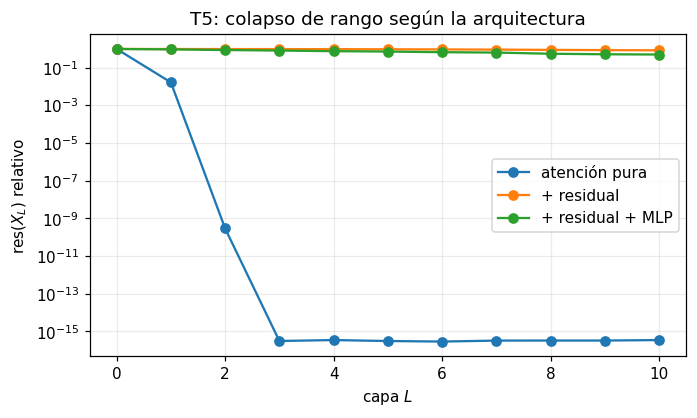

atención pura, res por capa: [9.72e-01 1.49e-02 1.68e-10 2.33e-16 3.66e-16]


In [13]:
# ---- Verificación del Teorema 5: colapso según arquitectura ----
def res_np(X): return np.linalg.norm(X - X.mean(0, keepdims=True)) / np.linalg.norm(X)
def spec(W): return W / np.linalg.norm(W, 2)
def simulate(use_res, use_mlp, L=10, n=24, d=24, seed=0):
    r = np.random.default_rng(seed); X = r.normal(size=(n, d)); X = X / np.linalg.norm(X) * np.sqrt(n); out = [res_np(X)]
    for _ in range(L):
        WQ, WK, WV = [spec(r.normal(size=(d, d))) for _ in range(3)]
        Y = softmax_np((X @ WQ) @ (X @ WK).T / np.sqrt(d)) @ (X @ WV); X = X + Y if use_res else Y
        if use_mlp:
            W1, W2 = r.normal(size=(d, 4 * d)) / np.sqrt(d), r.normal(size=(4 * d, d)) / np.sqrt(4 * d); X = X + np.maximum(0, X @ W1) @ W2
        out.append(res_np(X))
    return np.array(out)
plt.figure(figsize=(7, 3.8))
for ur, um, lab in [(False, False, "atención pura"), (True, False, "+ residual"), (True, True, "+ residual + MLP")]:
    plt.semilogy(np.mean([simulate(ur, um, seed=s) for s in range(8)], 0) + 1e-18, "o-", label=lab)
plt.xlabel("capa $L$"); plt.ylabel("res$(X_L)$ relativo"); plt.title("T5: colapso de rango según la arquitectura"); plt.legend(); plt.show()
print("atención pura, res por capa:", np.array2string(simulate(False, False)[:5], precision=2))

### **Teorema 6 (Gradientes en la inicialización: Pre-LN frente a Post-LN; Xiong et al., 2020)**
> **Teorema 6 (resumen, régimen de campo medio).** En la inicialización de un Transformer de $L$ capas y ancho $d$ grande:
> - **Post-LN** ($x_{l+1}=\mathrm{LN}(x_l+F_l(x_l))$): los gradientes cerca de la capa de salida son **grandes** (independientes de $L$ en orden), lo que exige *warm-up* del paso de aprendizaje.
> - **Pre-LN** ($x_{l+1}=x_l+F_l(\mathrm{LN}(x_l))$): los gradientes están **bien condicionados** y decrecen con la profundidad; el *warm-up* puede eliminarse.



#### **Desarrollo (jacobianos; el teorema de campo medio requiere [16])**
**¿Qué queremos demostrar?** Cómo cambia la derivada de una capa residual cuando LayerNorm actúa **antes** o **después** de la subcapa, y por qué ello afecta al gradiente.


**Paso 1 · Defina** $J_F=\partial F/\partial x$ y $J_{LN}=\partial LN/\partial x$. La regla de la cadena dice que la derivada de una composición es el producto de jacobianos en el orden correcto.

**Paso 2 · Pre-LN.** Si $y=x+F(LN(x))$, la derivada de $x$ es $I$ y la de la rama transformada es $J_F(LN(x))J_{LN}(x)$. Así,
$$\boxed{J_{\mathrm{Pre}}=I+J_F(LN(x))J_{LN}(x)}.$$
**Paso 3 · Post-LN.** Si $y=LN(x+F(x))$, la regla de la cadena da
$$\boxed{J_{\mathrm{Post}}=J_{LN}(x+F(x))(I+J_F(x))}.$$
**Paso 4 · Compare.** En **Pre-LN** existe un sumando identidad explícito; en **Post-LN** el jacobiano de normalización multiplica también a esa ruta. En varias capas, el gradiente depende del **producto** de estos jacobianos: no se puede concluir que nunca desaparezca o explote.

**Paso 5 · Ejemplo diferencial de LayerNorm.** Para un vector $z\in\mathbb R^d$, sin parámetros $\gamma,\beta$ y omitiendo $\varepsilon$, sea $\mu=d^{-1}\sum_i z_i$, $\sigma^2=d^{-1}\sum_i(z_i-\mu)^2$ y $\hat z=(z-\mu)/\sigma$. Entonces
$$J_{LN}(z)=\frac1\sigma\left(I-\frac{\mathbf1\mathbf1^\top}{d}-\frac{\hat z\hat z^\top}{d}\right).$$
Esto muestra que **normalizar cambia la propagación del gradiente**. Los resultados probabilísticos sobre su magnitud en la inicialización requieren los supuestos y las pruebas de Xiong et al. [16].

**Actividad experimental:** cambie `pre_ln=True/False` y compare curvas **sin prometer** que una variante será siempre mejor.

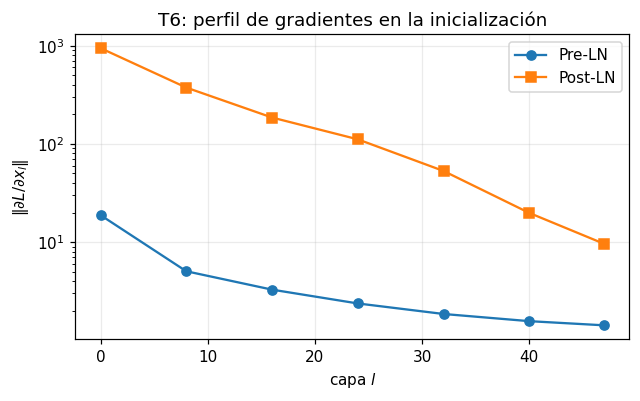

razón g(capa 0)/g(capa 47):  Pre-LN = 13.2  |  Post-LN = 98.6
magnitud absoluta en capa 0: Pre-LN = 18.8  |  Post-LN = 944.5


In [14]:
# ---- Verificación (tendencia) del Teorema 6 ----
def ln_np(x): return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-9)
def grad_profile(arch, L=48, d=64, seed=0, probe=(0, 8, 16, 24, 32, 40, 47)):
    r = np.random.default_rng(seed); Ws = [r.normal(size=(d, d)) * np.sqrt(2 / d) for _ in range(L)]; c, x0 = r.normal(size=d), r.normal(size=d)
    def layer(W, x):
        f = np.maximum(0, W @ (ln_np(x) if arch == "pre" else x)); return x + f if arch == "pre" else ln_np(x + f)
    def loss_from(l, xin):
        x = xin
        for W in Ws[l:]: x = layer(W, x)
        return c @ (ln_np(x) if arch == "pre" else x)
    xs = [x0]
    for W in Ws: xs.append(layer(W, xs[-1]))
    out = []
    for l in probe:
        g = np.zeros(d)
        for i in range(d):
            e = np.zeros(d); e[i] = 1e-5; g[i] = (loss_from(l, xs[l] + e) - loss_from(l, xs[l] - e)) / 2e-5
        out.append(np.linalg.norm(g))
    return np.array(out)
probe = (0, 8, 16, 24, 32, 40, 47)
pre, post = np.mean([grad_profile("pre", seed=s) for s in range(5)], 0), np.mean([grad_profile("post", seed=s) for s in range(5)], 0)
plt.figure(figsize=(6.5, 3.6)); plt.semilogy(probe, pre, "o-", label="Pre-LN"); plt.semilogy(probe, post, "s-", label="Post-LN")
plt.xlabel("capa $l$"); plt.ylabel(r"$\|\partial L/\partial x_l\|$"); plt.title("T6: perfil de gradientes en la inicialización"); plt.legend(); plt.show()
print(f"razón g(capa 0)/g(capa 47):  Pre-LN = {pre[0]/pre[-1]:.1f}  |  Post-LN = {post[0]/post[-1]:.1f}")
print(f"magnitud absoluta en capa 0: Pre-LN = {pre[0]:.1f}  |  Post-LN = {post[0]:.1f}")

In [15]:
# ---- Experimento en TF: Pre-LN vs Post-LN con LR alto y SIN warm-up (reporte lo que obtenga) ----
def train_variant(pre_ln, lr, epochs=2, seed=0):
    tf.random.set_seed(seed)
    m = TinyGPT(V, d_model=64, n_heads=4, n_layers=6, d_ff=192, pre_ln=pre_ln, rope=True)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    return m.fit(ds_tr, validation_data=ds_va, epochs=epochs, verbose=0).history["val_loss"]
for lr in [1e-3, 5e-3]:
    for pre in [True, False]:
        print(f"lr={lr:.0e}  {'Pre-LN ' if pre else 'Post-LN'}  val_loss por época: {np.round(train_variant(pre, lr), 3)}")

/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_5', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:42

lr=1e-03  Pre-LN   val_loss por época: [0.315 0.245]


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_10', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_11', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:

lr=1e-03  Post-LN  val_loss por época: [0.292 0.242]


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_16', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_17', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:

lr=5e-03  Pre-LN   val_loss por época: [0.297 0.245]


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_22', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_23', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:

lr=5e-03  Post-LN  val_loss por época: [2.74 2.74]




## **F. Atención eficiente e inferencia**

La **atención estándar** construye una matriz de puntuaciones $S\in\mathbb{R}^{n\times n}$, cuya memoria crece como $O(n^2)$. En GPU, uno de los principales cuellos de botella puede ser la transferencia de datos entre la **memoria HBM y la memoria rápida SRAM**, además del costo computacional.

**FlashAttention** [19] evita almacenar la matriz completa de atención mediante un procesamiento **por bloques (*tiling*)**, utilizando un algoritmo de **softmax en línea (*online softmax*)** que conserva la exactitud matemática del resultado.

### **Teorema 7. Softmax en línea y exactitud de la atención por bloques**

**Enunciado.** Sea $\boldsymbol{s}\in\mathbb{R}^{N}$ un vector de puntuaciones dividido en bloques $B_1,\ldots,B_T$. Definimos el **máximo acumulado** $m_t$ y el **denominador normalizado** $\ell_t$:

$$
\boxed{
\begin{aligned}
m_t&=\max\left(m_{t-1},\max_{i\in B_t}s_i\right),\\
\ell_t&=e^{m_{t-1}-m_t}\ell_{t-1}
+\sum_{i\in B_t}e^{s_i-m_t}.
\end{aligned}
}
$$

Inicializamos $m_0=-\infty$ y $\ell_0=0$, interpretando la contribución acumulada inicial como cero.

**Teorema 7.** El procesamiento por bloques satisface:

**(i) Exactitud del softmax:** al finalizar los $T$ bloques,

$$
\boxed{
m_T=\max_i s_i,\qquad
\ell_T=\sum_{i=1}^{N}e^{s_i-m_T}
}
$$

Por tanto, cada probabilidad puede calcularse exactamente como:

$$
\operatorname{softmax}(\boldsymbol{s})_i
=\frac{e^{s_i-m_T}}{\ell_T}.
$$

**(ii) Exactitud de la atención:** si $\boldsymbol{v}_i$ es el vector de valores asociado a $s_i$, definimos el numerador acumulado:

$$
\boxed{
\boldsymbol{o}_t=
e^{m_{t-1}-m_t}\boldsymbol{o}_{t-1}
+\sum_{i\in B_t}e^{s_i-m_t}\boldsymbol{v}_i
}
$$

con $\boldsymbol{o}_0=\boldsymbol{0}$. Entonces:

$$
\boxed{
\frac{\boldsymbol{o}_T}{\ell_T}
=\operatorname{softmax}(\boldsymbol{s})V
}
$$

**Consecuencia:** la atención puede calcularse sin materializar la matriz completa de puntuaciones. FlashAttention utiliza memoria adicional lineal para las estadísticas por fila y evita la memoria cuadrática de la atención estándar.

### **Demostración por inducción**

**¿Qué queremos demostrar?** Que procesar las puntuaciones por bloques, actualizando el máximo y renormalizando los acumuladores, produce **exactamente el mismo resultado matemático** que calcular el softmax sobre todas las puntuaciones simultáneamente.

**Paso 1. Establecer el invariante.** Sea $A_t=B_1\cup\cdots\cup B_t$ el conjunto de índices procesados. Queremos demostrar que, después del bloque $t$:

$$
\boxed{
\begin{aligned}
m_t&=\max_{i\in A_t}s_i,\\
\ell_t&=\sum_{i\in A_t}e^{s_i-m_t},\\
\boldsymbol{o}_t&=\sum_{i\in A_t}e^{s_i-m_t}\boldsymbol{v}_i.
\end{aligned}
}
$$

**Paso 2. Caso base ($t=1$).** Para el primer bloque calculamos:

$$
\begin{aligned}
m_1&=\max_{i\in B_1}s_i,\\
\ell_1&=\sum_{i\in B_1}e^{s_i-m_1},\\
\boldsymbol{o}_1&=\sum_{i\in B_1}e^{s_i-m_1}\boldsymbol{v}_i.
\end{aligned}
$$

Estas expresiones coinciden con el invariante para $A_1=B_1$. Por tanto, **el caso base se cumple**.

**Paso 3. Hipótesis inductiva y cambio de máximo.** Supongamos que el invariante es válido después del bloque $t-1$. Al incorporar el bloque $B_t$, el nuevo máximo es:

$$
m_t=\max\left(m_{t-1},\max_{i\in B_t}s_i\right).
$$

Para cualquier puntuación anterior se cumple:

$$
\boxed{
e^{s_i-m_{t-1}}e^{m_{t-1}-m_t}
=e^{s_i-m_t}
}
$$

Esta identidad demuestra que **multiplicar los acumuladores anteriores por $e^{m_{t-1}-m_t}$ permite expresarlos respecto al nuevo máximo**, sin alterar su contribución matemática.

**Paso 4. Actualizar los acumuladores.** Aplicamos la identidad anterior y añadimos las contribuciones del nuevo bloque:

$$
\begin{aligned}
\ell_t
&=e^{m_{t-1}-m_t}\ell_{t-1}
+\sum_{i\in B_t}e^{s_i-m_t}\\
&=\sum_{i\in A_{t-1}}e^{s_i-m_t}
+\sum_{i\in B_t}e^{s_i-m_t}\\
&=\boxed{\sum_{i\in A_t}e^{s_i-m_t}}.
\end{aligned}
$$

Análogamente, para el numerador de la atención:

$$
\begin{aligned}
\boldsymbol{o}_t
&=e^{m_{t-1}-m_t}\boldsymbol{o}_{t-1}
+\sum_{i\in B_t}e^{s_i-m_t}\boldsymbol{v}_i\\
&=\sum_{i\in A_{t-1}}e^{s_i-m_t}\boldsymbol{v}_i
+\sum_{i\in B_t}e^{s_i-m_t}\boldsymbol{v}_i\\
&=\boxed{\sum_{i\in A_t}e^{s_i-m_t}\boldsymbol{v}_i}.
\end{aligned}
$$

Por tanto, **el invariante se conserva después de incorporar cada bloque**.

**Paso 5. Normalizar al finalizar.** Por inducción, el resultado es válido para los $T$ bloques. Dividiendo el numerador acumulado por el denominador:

$$
\begin{aligned}
\frac{\boldsymbol{o}_T}{\ell_T}
&=\frac{\sum_{i=1}^{N}e^{s_i-m_T}\boldsymbol{v}_i}
{\sum_{i=1}^{N}e^{s_i-m_T}}\\
&=\sum_{i=1}^{N}
\operatorname{softmax}(\boldsymbol{s})_i\boldsymbol{v}_i\\
&=\boxed{\operatorname{softmax}(\boldsymbol{s})V}.
\end{aligned}
$$

**Conclusión.** Queda demostrado que **la atención por bloques es matemáticamente equivalente a la atención convencional**, salvo las diferencias producidas por el redondeo numérico. La principal ventaja de FlashAttention consiste en **reducir las transferencias de memoria**, evitando almacenar la matriz completa de atención.

### **Complejidad computacional y de memoria**

| **Propiedad** | **Atención estándar** | **FlashAttention** |
|---|---|---|
| Matriz de atención | Se materializa, $O(n^2)$ | No se materializa |
| Memoria de activaciones de atención | $O(n^2)$ | $O(n)$ para estadísticas por fila |
| Operaciones aritméticas | $O(n^2d)$ | $O(n^2d)$ |
| Accesos a HBM | Elevados | Reducidos mediante bloques |

En el régimen analizado por FlashAttention [19], con memoria SRAM de capacidad $M$ y bajo las hipótesis de tamaño de bloques correspondientes, la complejidad de acceso a memoria puede reducirse a:

$$
\boxed{
\Theta\left(\frac{n^2d^2}{M}\right)
}
$$

Este resultado corresponde al **análisis de transferencias de memoria**, no a una disminución del orden cuadrático de las operaciones aritméticas.

FlashAttention no modifica la definición matemática de la atención; **optimiza la manera de calcularla y almacenar sus resultados intermedios**, aprovechando eficientemente la jerarquía de memoria de las GPU.


(i) m == max(x): True | |ℓ − Σexp(x−max)| = 0.00e+00
(ii) bloque= 16: máx |Flash − exacta| = 2.01e-07
(ii) bloque= 64: máx |Flash − exacta| = 2.09e-07
(ii) bloque=256: máx |Flash − exacta| = 2.68e-07
causal: máx |Flash − exacta| = 3.28e-07


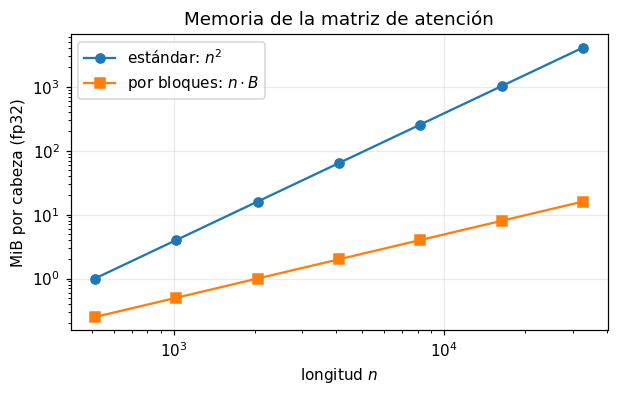

In [16]:
# ---- Verificación del Teorema 7 ----
def online_softmax_stats(x, block=64):
    m, l = -np.inf, 0.0
    for i in range(0, len(x), block):
        xb = x[i:i + block]; m_new = max(m, xb.max()); l = l * np.exp(m - m_new) + np.exp(xb - m_new).sum(); m = m_new
    return m, l
x = np.random.randn(5000) * 40
m, l = online_softmax_stats(x)
print(f"(i) m == max(x): {m == x.max()} | |ℓ − Σexp(x−max)| = {abs(l - np.exp(x - x.max()).sum()):.2e}")

def flash_attention_tf(Q, K, V, block=64, causal=False):
    n, d = Q.shape; m = tf.fill((n,), -np.inf); l = tf.zeros((n,)); O = tf.zeros((n, d))
    for j in range(0, n, block):
        Kj, Vj = K[j:j + block], V[j:j + block]
        S = tf.matmul(Q, Kj, transpose_b=True) / math.sqrt(d)
        if causal:
            qi = tf.range(n)[:, None]; kj = tf.range(j, j + Kj.shape[0])[None]; S = tf.where(kj <= qi, S, -1e9)
        m_new = tf.maximum(m, tf.reduce_max(S, axis=1)); P = tf.exp(S - m_new[:, None]); alpha = tf.exp(m - m_new)
        l = alpha * l + tf.reduce_sum(P, axis=1); O = alpha[:, None] * O + tf.matmul(P, Vj); m = m_new
    return O / l[:, None]

n, d = 512, 32; Q, K, Vv = [tf.random.normal((n, d)) for _ in range(3)]
exact = tf.nn.softmax(tf.matmul(Q, K, transpose_b=True) / math.sqrt(d), axis=-1) @ Vv
for blk in [16, 64, 256]: print(f"(ii) bloque={blk:3d}: máx |Flash − exacta| = {tf.reduce_max(tf.abs(flash_attention_tf(Q, K, Vv, blk) - exact)).numpy():.2e}")
mask = tf.linalg.band_part(tf.ones((n, n)), -1, 0)
exact_c = tf.nn.softmax(tf.matmul(Q, K, transpose_b=True) / math.sqrt(d) + (1 - mask) * -1e9, axis=-1) @ Vv
print(f"causal: máx |Flash − exacta| = {tf.reduce_max(tf.abs(flash_attention_tf(Q, K, Vv, 64, causal=True) - exact_c)).numpy():.2e}")

ns = np.array([512, 1024, 2048, 4096, 8192, 16384, 32768])
plt.figure(figsize=(6.3, 3.5)); plt.loglog(ns, ns.astype(float)**2 * 4 / 2**20, "o-", label="estándar: $n^2$"); plt.loglog(ns, ns.astype(float) * 128 * 4 / 2**20, "s-", label="por bloques: $n\\cdot B$")
plt.xlabel("longitud $n$"); plt.ylabel("MiB por cabeza (fp32)"); plt.title("Memoria de la matriz de atención"); plt.legend(); plt.show()

### **KV-cache, MQA y GQA**
En generación, al producir el token $t$ se **reutilizan** claves y valores de los tokens previos. El **KV-cache** reduce el coste por token de $O(t\,d^2)$ a $O(d^2+t\,d)$, pero consume memoria:
$$\text{Mem}_{KV}=2\cdot L\cdot n\cdot h_{kv}\cdot d_h\cdot b\quad\text{(bytes)}.$$
**MHA:** $h_{kv}=h$. **MQA** (Shazeer 2019 [26]): $h_{kv}=1$. **GQA** (Ainslie et al. 2023 [13]): $1<h_{kv}<h$. Como la generación está limitada por **ancho de banda de memoria**, reducir $h_{kv}$ acelera la inferencia.

In [17]:
def kv_gib(L, n, d_head, h_kv, bytes_=2, batch=1): return 2 * L * n * h_kv * d_head * bytes_ * batch / 2**30
print("KV-cache (L=32, d_head=128, n=8192, fp16, batch=1):")
for nm, hk in [("MHA  h_kv=32", 32), ("GQA  h_kv=8", 8), ("MQA  h_kv=1", 1)]: print(f"  {nm:14s}: {kv_gib(32, 8192, 128, hk):6.2f} GiB")

class CachedAttn(layers.Layer):
    def __init__(self, d, h, **kw):
        super().__init__(**kw); self.h, self.dh = h, d // h; self.wq, self.wk, self.wv, self.wo = [layers.Dense(d, use_bias=False) for _ in range(4)]
    def heads(self, x): B, n = tf.shape(x)[0], tf.shape(x)[1]; return tf.transpose(tf.reshape(x, (B, n, self.h, self.dh)), (0, 2, 1, 3))
    def full(self, x):
        q, k, v = self.heads(self.wq(x)), self.heads(self.wk(x)), self.heads(self.wv(x)); n = tf.shape(x)[1]
        s = tf.matmul(q, k, transpose_b=True) / math.sqrt(self.dh) + (1 - tf.linalg.band_part(tf.ones((n, n)), -1, 0)) * -1e9
        return self.wo(tf.reshape(tf.transpose(tf.matmul(tf.nn.softmax(s), v), (0, 2, 1, 3)), tf.shape(x)))
    def step(self, x_t, cache):
        q = self.heads(self.wq(x_t)); k_t, v_t = self.heads(self.wk(x_t)), self.heads(self.wv(x_t))
        K = k_t if cache is None else tf.concat([cache[0], k_t], 2); Vc = v_t if cache is None else tf.concat([cache[1], v_t], 2)
        o = tf.matmul(tf.nn.softmax(tf.matmul(q, K, transpose_b=True) / math.sqrt(self.dh)), Vc)
        return self.wo(tf.reshape(tf.transpose(o, (0, 2, 1, 3)), tf.shape(x_t))), (K, Vc)

att = CachedAttn(64, 4); x = tf.random.normal((1, 20, 64)); full = att.full(x); cache = None; outs = []
for t in range(20): o, cache = att.step(x[:, t:t + 1], cache); outs.append(o)
print("KV-cache == recomputar todo:", np.allclose(tf.concat(outs, 1).numpy(), full.numpy(), atol=1e-5))
T = np.arange(1, 2049); print(f"pares query-key al generar 2048 tokens: sin cache {int(np.cumsum(T*(T+1)/2)[-1]):,} | con cache {int(np.cumsum(T)[-1]):,}")

KV-cache (L=32, d_head=128, n=8192, fp16, batch=1):
  MHA  h_kv=32  :   4.00 GiB
  GQA  h_kv=8   :   1.00 GiB
  MQA  h_kv=1   :   0.12 GiB
KV-cache == recomputar todo: True
pares query-key al generar 2048 tokens: sin cache 1,433,753,600 | con cache 2,098,176



## **G. Leyes de escalamiento**
**Definición (ley tipo Chinchilla).** La pérdida se modela como
$$\boxed{L(N,D)=E+\frac{A}{N^{\alpha}}+\frac{B}{D^{\beta}}},\qquad C\approx6ND,$$
con $E$ la entropía irreducible, $N$ parámetros, $D$ tokens y $C$ FLOPs de entrenamiento (6 por parámetro y token: 2 *forward* + 4 *backward*).

### Teorema 8 (Asignación óptima de cómputo; Hoffmann et al., 2022)
> **Teorema 8.** Minimizando $L(N,D)$ sujeto a $6ND=C$ (con $\alpha,\beta>0$), el óptimo es
> $$N^\star(C)=G\Big(\tfrac C6\Big)^{\frac{\beta}{\alpha+\beta}},\qquad D^\star(C)=G^{-1}\Big(\tfrac C6\Big)^{\frac{\alpha}{\alpha+\beta}},\qquad G=\Big(\tfrac{\alpha A}{\beta B}\Big)^{\frac1{\alpha+\beta}}.$$
> Luego $N^\star\propto C^{a}$, $D^\star\propto C^{b}$ con $a=\tfrac{\beta}{\alpha+\beta}$, $b=\tfrac{\alpha}{\alpha+\beta}$ y **$a+b=1$**. Con los valores ajustados por Hoffmann et al. ($\alpha\approx0.34,\ \beta\approx0.28$): $a\approx0.45,\ b\approx0.55$, es decir, **modelo y datos deben crecer casi a la par**. Kaplan et al. [27] habían estimado un exponente de $N$ mayor (favoreciendo modelos más grandes con menos datos); la diferencia se atribuye a la metodología de ajuste.


#### **Demostración.**
**¿Qué queremos demostrar?** Cómo distribuir un presupuesto de cómputo fijo entre número de parámetros $N$ y datos $D$ para minimizar una función de pérdida propuesta, y por qué la solución es el mínimo global.

**Paso 1 · Escriba el problema restringido.** Minimice $L(N,D)=E+AN^{-\alpha}+BD^{-\beta}$ con $N>0,D>0$ y $6ND=C$; las constantes $A,B,\alpha,\beta,C$ son positivas.

**Paso 2 · Despeje una variable.** De la restricción: $D=C/(6N)$. Sustituya:
$$f(N)=E+AN^{-\alpha}+B\left(\frac{6N}{C}\right)^\beta.$$
**Paso 3 · Derive respecto a $N$.** Usando $\frac{d}{dN}N^r=rN^{r-1}$,
$$f'(N)=-\alpha AN^{-\alpha-1}+\beta B\left(\frac{6}{C}\right)^\beta N^{\beta-1}.$$
**Paso 4 · Imponga la condición de primer orden.** $f'(N^*)=0$ significa
$$\alpha A(N^*)^{-\alpha-1}=\beta B(6/C)^\beta(N^*)^{\beta-1}.$$
Multiplique ambos lados por $(N^*)^{\alpha+1}$ y divida por $\beta B(6/C)^\beta$:
$$\boxed{(N^*)^{\alpha+\beta}=\frac{\alpha A}{\beta B}\left(\frac C6\right)^\beta}.$$
**Paso 5 · Extraiga la raíz.** Definiendo $G=[\alpha A/(\beta B)]^{1/(\alpha+\beta)}$ resulta
$$N^*=G(C/6)^{\beta/(\alpha+\beta)},\qquad D^*=\frac{C}{6N^*}=G^{-1}(C/6)^{\alpha/(\alpha+\beta)}.$$
**Paso 6 · Justifique que es mínimo global.** Para $z=\log N$, $f(e^z)=E+Ae^{-\alpha z}+B(6/C)^\beta e^{\beta z}$ y
$$\frac{d^2 f(e^z)}{dz^2}=\alpha^2Ae^{-\alpha z}+\beta^2B(6/C)^\beta e^{\beta z}>0.$$
Es estrictamente convexa en $z$, por lo que el punto crítico es el **único mínimo global**. $\blacksquare$

exponentes: N* ∝ C^0.452   D* ∝ C^0.548   (suman 1.0)
       C   N* cerrada  N* numérica  err. rel.    D/N     L*
   1e+21    1.824e+09    1.824e+09    1.2e-05   50.1  2.329
   1e+22    5.160e+09    5.161e+09    9.2e-06   62.6  2.139
   1e+23    1.460e+10    1.460e+10    3.1e-05   78.2  2.005
   1e+24    4.130e+10    4.129e+10    5.1e-05   97.7  1.911


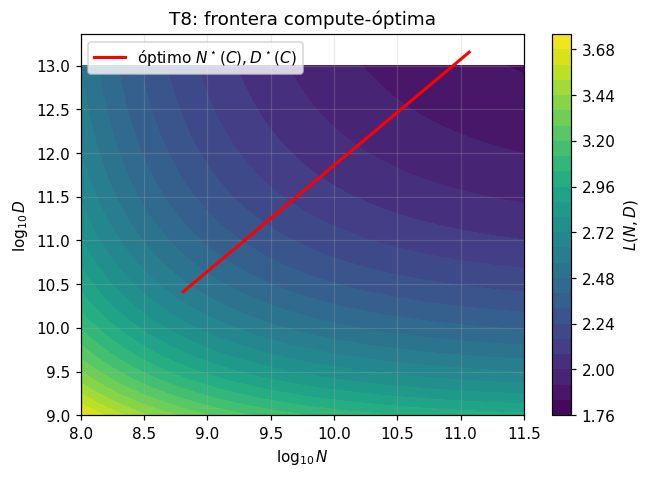

In [18]:
# ---- Verificación del Teorema 8: fórmula cerrada vs. minimización numérica ----
E_, A_, B_, al, be = 1.69, 406.4, 410.7, 0.34, 0.28            # Hoffmann et al. 2022 (ajuste publicado)
G = (al * A_ / (be * B_)) ** (1 / (al + be))
def closed(C): return G * (C / 6) ** (be / (al + be)), (C / 6) ** (al / (al + be)) / G
def numeric(C):
    Ns = np.logspace(5, 14, 200000); Ds = C / (6 * Ns); L = E_ + A_ / Ns**al + B_ / Ds**be; i = L.argmin(); return Ns[i], Ds[i], L[i]
print(f"exponentes: N* ∝ C^{be/(al+be):.3f}   D* ∝ C^{al/(al+be):.3f}   (suman {be/(al+be)+al/(al+be):.1f})")
print(f"{'C':>8} {'N* cerrada':>12} {'N* numérica':>12} {'err. rel.':>10} {'D/N':>6} {'L*':>6}")
for C in [1e21, 1e22, 1e23, 1e24]:
    Nc, Dc = closed(C); Nn, Dn, Ln = numeric(C); print(f"{C:8.0e} {Nc:12.3e} {Nn:12.3e} {abs(Nc-Nn)/Nn:10.1e} {Dc/Nc:6.1f} {Ln:6.3f}")
Ns, Ds = np.logspace(8, 11.5, 200), np.logspace(9, 13, 200); NN, DD = np.meshgrid(Ns, Ds); LL = E_ + A_ / NN**al + B_ / DD**be
plt.figure(figsize=(6.5, 4.5)); cs = plt.contourf(np.log10(NN), np.log10(DD), LL, 25, cmap="viridis"); plt.colorbar(cs, label="$L(N,D)$")
fr = np.array([closed(c) for c in np.logspace(20, 25, 50)]); plt.plot(np.log10(fr[:, 0]), np.log10(fr[:, 1]), "r-", lw=2, label="óptimo $N^\\star(C),D^\\star(C)$")
plt.xlabel("$\\log_{10}N$"); plt.ylabel("$\\log_{10}D$"); plt.title("T8: frontera compute-óptima"); plt.legend(); plt.show()


## **H. Expresividad y límites teóricos**
Dos preguntas complementarias: ¿**qué** puede aproximar un Transformer? y ¿**qué no** puede computar bajo supuestos realistas?

### **Teorema 9 (Aproximación universal; Yun et al., 2020)**
> **Teorema 9.** Sea $1\le p<\infty$, $\varepsilon>0$ y $\mathcal{D}\subset\mathbb{R}^{d\times n}$ **compacto**. Con tamaños de cabeza y de FFN **fijos** (independientes de $n$ y $d$):
> 1. **(Equivariantes)** Para toda $f$ continua y **equivariante a permutaciones** existe un Transformer $g$ con $d_p(f,g)=\big(\int_{\mathcal{D}}\|f(X)-g(X)\|_p^p\,dX\big)^{1/p}<\varepsilon$.
> 2. **(Con codificación posicional)** Para toda $f$ continua (sin restricción de simetría) existe un Transformer con **codificación posicional entrenable** con $d_p(f,g)<\varepsilon$.
>
> **Salvedades.** (a) Aproximación en norma $L^p$, no uniforme. (b) Es un resultado de **existencia**: el número de capas puede ser enorme y **no** dice nada sobre aprendibilidad por descenso de gradiente. (c) Las **FFN son imprescindibles** (consistente con T5). (d) Una capa de atención aislada **no** es aproximador universal.


#### **Construcción intuitiva, paso a paso (no sustituye la prueba de [3])**
**¿Qué queremos demostrar?** Por qué una arquitectura con atención, proyecciones y FFN puede aproximar funciones de secuencias bajo hipótesis precisas. **Alcance:** describimos la construcción, no reproducimos la prueba completa del artículo.


**Paso 1 · Utilice compacidad y continuidad.** En un dominio compacto, una función continua es uniformemente continua. Por tanto, si dos entradas están suficientemente próximas, sus salidas también lo estarán.

**Paso 2 · Discretice el dominio.** Particione el espacio de entradas en celdas pequeñas; aproxime $f$ por una función que asigna a cada celda un valor representativo. Al refinar la partición, el error de aproximación disminuye en la métrica de interés.

**Paso 3 · Codifique la celda con FFN.** Una red feed-forward suficientemente construida puede producir representaciones que distinguen regiones discretizadas del espacio de entrada.

**Paso 4 · Conecte posiciones con atención.** Varias capas de atención pueden crear una representación contextual que permite que cada token acceda a información de todos los demás. La construcción formal del artículo usa mecanismos de selección y una codificación contextual que distingue configuraciones relevantes.

**Paso 5 · Recupere los valores.** Una FFN final transforma el código contextual en la salida asignada a la celda correspondiente. Con **posiciones**, es posible distinguir secuencias que solo difieren en el orden; sin posiciones, queda la restricción de equivarianza de T1.

**Qué demuestra y qué no:** esto explica la **estrategia constructiva** del teorema, pero las cotas de error y la construcción formal de las capas deben consultarse en [3]. Aproximar una función en $L^p$ **no garantiza** que el entrenamiento habitual encuentre los pesos necesarios.

In [19]:
# ---- Ilustración de T1 + T9: equivariante vs. no equivariante, con y sin codificación posicional ----
rng = np.random.default_rng(0); n_, d_ = 8, 4
def make(task, N=6000):
    X = rng.normal(size=(N, n_, d_)).astype("float32"); Y = (X - X.mean(1, keepdims=True)) if task == "center" else X[:, ::-1, :]
    return X, Y.astype("float32")
def build(use_pe):
    inp = keras.Input((n_, d_)); h = layers.Dense(64)(inp)
    if use_pe: h = h + layers.Embedding(n_, 64)(tf.range(n_))[None]
    for _ in range(2): h = TransformerBlock(64, 4, 128, pre_ln=True, dropout=0.0)(h)
    return keras.Model(inp, layers.Dense(d_)(h))
res = {}
for task in ["center", "reverse"]:
    X, Y = make(task); Xt, Yt = make(task, 1000)
    for use_pe in [False, True]:
        m = build(use_pe); m.compile(keras.optimizers.Adam(2e-3), "mse"); m.fit(X, Y, epochs=25, batch_size=128, verbose=0); res[(task, use_pe)] = m.evaluate(Xt, Yt, verbose=0)
print(f"{'tarea':10s} {'sin PE':>10s} {'con PE':>10s}   (MSE de prueba; varianza de la salida ≈ 1.0)")
for task in ["center", "reverse"]: print(f"{task:10s} {res[(task, False)]:10.4f} {res[(task, True)]:10.4f}")
print("Lectura: 'reverse' no es equivariante, así que SIN PE no puede aprenderse (T1); con PE sí (T9.2). 'center' es equivariante y no necesita PE.")

/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_28', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_29', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:

tarea          sin PE     con PE   (MSE de prueba; varianza de la salida ≈ 1.0)
center         0.0006     0.0009
reverse        0.8923     0.0036
Lectura: 'reverse' no es equivariante, así que SIN PE no puede aprenderse (T1); con PE sí (T9.2). 'center' es equivariante y no necesita PE.


### **Teorema 10 (Límites de expresividad con precisión finita; Hahn 2020, Merrill y Sabharwal 2023–24)**
Cada parte vale **bajo supuestos concretos**; léalas con sus hipótesis.

> **Teorema 10 (resumen en tres partes).**
> **(a) [Hahn, 2020]** Para Transformers con **número fijo de capas y cabezas** y *hard attention*, el lenguaje $\mathrm{PARITY}=\{w\in\{0,1\}^*:\#_1(w)\ \text{par}\}$ **no es reconocible**; para *soft attention*, la entropía cruzada por token sobre PARITY o Dyck-2 se acerca a la de un predictor trivial cuando $n\to\infty$ (forma cuantitativa exacta en [34]; aquí sólo se afirma la tendencia).
> **(b) [Merrill y Sabharwal, 2023]** Todo Transformer de **profundidad constante** y **precisión logarítmica** ($c\log n$ bits) puede simularse por circuitos **$\mathsf{TC}^0$** uniformes en espacio logarítmico. Por tanto, **si** $\mathsf{TC}^0\neq\mathsf{NC}^1$ (conjetura estándar), esos Transformers **no** resuelven problemas $\mathsf{NC}^1$-completos; ejemplos citados en [35]: la **composición de permutaciones de $S_5$** y la **evaluación de fórmulas booleanas**. *(No debe concluirse nada general sobre otros problemas sin analizar su clase de complejidad.)*
> **(c) [Merrill y Sabharwal, 2024; Li et al., 2024]** Estas limitaciones **se relajan** con **chain of thought**: con $\mathrm{poly}(n)$ tokens intermedios el decoder-only puede resolver problemas de $\mathsf{P}$ (bajo condiciones de uniformidad); el CoT aporta **cómputo serial** que la profundidad constante no tiene.
>
> **Salvedades.** (i) (a) *no* implica que PARITY sea imposible en la práctica: **Chiang y Cholak (2022)** [36] dan construcciones explícitas que la reconocen para todas las longitudes. (ii) (b) exige **precisión logarítmica**. (iii) Las cotas $\mathsf{TC}^0$ son **superiores** de expresividad y **condicionales** a una conjetura de complejidad.



#### **Esquema explicativo de la cota $\mathsf{TC}^{0}$ (prueba técnica en [35])**
**¿Qué queremos demostrar?** En qué condiciones un Transformer de profundidad fija y precisión limitada puede simularse con circuitos de umbral de profundidad constante; esto establece un límite **condicional** de expresividad.


**Paso 1 · Qué es un circuito.** Un circuito booleano transforma bits de entrada en bits de salida. **Profundidad constante** significa que el número máximo de operaciones conectadas sucesivamente está acotado independientemente de la longitud $n$.

**Paso 2 · Cuantifique los números.** Suponga que cada número intermedio se representa con $O(\log n)$ bits; este supuesto de **precisión** es indispensable para aplicar el resultado.

**Paso 3 · Reemplace operaciones por circuitos.** Los productos escalares, agregaciones, transformaciones elementales aproximadas y normalizaciones pueden implementarse en familias de circuitos de umbral de profundidad constante bajo las hipótesis técnicas del artículo.

**Paso 4 · Componga las capas.** Si cada bloque admite profundidad acotada y hay un número **fijo** de bloques, su composición mantiene profundidad acotada. De aquí se obtiene la inclusión en $\mathsf{TC}^{0}$.

**Paso 5 · Explique el límite condicional.** Si se supone $\mathsf{TC}^{0}\neq\mathsf{NC}^{1}$, no se obtiene un algoritmo de profundidad constante para todos los problemas completos de $\mathsf{NC}^{1}$. **No es una demostración** de la separación entre estas clases: la separación sigue siendo abierta.

**Diferencia crucial:** generar tokens intermedios durante un razonamiento (*chain-of-thought*) agrega pasos secuenciales; esa ejecución no equivale a mantener una cantidad fija de cómputo por entrada. Para la formulación rigurosa, consultar [35, 38, 39].

In [23]:
mm.compile(keras.optimizers.Adam(1e-3),
           keras.losses.SparseCategoricalCrossentropy(from_logits=True),
           ["accuracy"])

/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_38', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_39', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


n= 6 | precisión=1.000 | azar=0.500


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_40', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_41', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


n=10 | precisión=0.515 | azar=0.500


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_42', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_43', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


n=14 | precisión=0.500 | azar=0.500


/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_44', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_45', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


n=18 | precisión=0.499 | azar=0.500


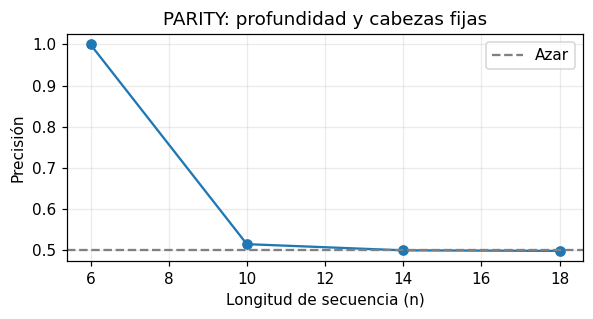

/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_46', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_47', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


PARIDAD PREFIJO | precisión por token = 0.720
Interpretar resultados considerando la generalización y la supervisión por token.


In [24]:

# EXPERIMENTO T10: PARIDAD Y TRANSFORMERS
rng = np.random.default_rng(1)

# 1. Generar secuencias binarias y calcular su paridad
def parity_data(N, n):
    X = rng.integers(0, 2, size=(N, n)).astype("int32")
    return X, (X.sum(axis=1) % 2).astype("int32")

# 2. Transformer clasificador con profundidad fija
def build_cls(n, d=64, layers_=2):
    inp = keras.Input(shape=(n,), dtype="int32")
    h = layers.Embedding(2, d)(inp)
    h = h + layers.Embedding(n, d)(tf.range(n))[None, :, :]

    for _ in range(layers_):
        h = TransformerBlock(d, 4, 4*d, pre_ln=True, dropout=0.0)(h)

    out = layers.Dense(2)(layers.GlobalAveragePooling1D()(h))
    return keras.Model(inp, out)

# 3. Entrenar y comparar diferentes longitudes
acc_by_n = {}

for n_try in [6, 10, 14, 18]:
    Xa, ya = parity_data(30000, n_try)
    Xb, yb = parity_data(3000, n_try)

    mm = build_cls(n_try)
    mm.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )

    mm.fit(Xa, ya, epochs=30, batch_size=256, verbose=0)
    resultado = mm.evaluate(Xb, yb, verbose=0, return_dict=True)
    acc_by_n[n_try] = resultado["accuracy"]

    print(f"n={n_try:2d} | precisión={acc_by_n[n_try]:.3f} | azar=0.500")

# 4. Visualizar precisión según longitud
plt.figure(figsize=(5.5, 3))
plt.plot(list(acc_by_n), list(acc_by_n.values()), "o-")
plt.axhline(0.5, color="gray", ls="--", label="Azar")
plt.xlabel("Longitud de secuencia (n)")
plt.ylabel("Precisión")
plt.title("PARITY: profundidad y cabezas fijas")
plt.legend()
plt.tight_layout()
plt.show()

# 5. PARIDAD PREFIJO: supervisión por token
def parity_cot(N, n):
    X = rng.integers(0, 2, size=(N, n)).astype("int32")
    return X, (np.cumsum(X, axis=1) % 2).astype("int32")

n_tr = 12
Xc, Pc = parity_cot(30000, n_tr)

inp = keras.Input(shape=(n_tr,), dtype="int32")
h = layers.Embedding(2, 64)(inp)
h = h + layers.Embedding(n_tr, 64)(tf.range(n_tr))[None, :, :]

for _ in range(2):
    h = TransformerBlock(
        64, 4, 256, causal=True, pre_ln=True, dropout=0.0
    )(h)

mc = keras.Model(inp, layers.Dense(2)(h))
mc.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

mc.fit(Xc, Pc, epochs=25, batch_size=256, verbose=0)
Xcv, Pcv = parity_cot(3000, n_tr)
resultado = mc.evaluate(Xcv, Pcv, verbose=0, return_dict=True)

print(f"PARIDAD PREFIJO | precisión por token = {resultado['accuracy']:.3f}")
print("Interpretar resultados considerando la generalización y la supervisión por token.")



## **I. Interpretabilidad mecanicista: circuitos e induction heads**
Elhage et al. [41] formalizan el Transformer con una vista **lineal**.

**Flujo residual.** Cada capa **lee** del flujo residual $x\in\mathbb{R}^{d}$ y **escribe** una actualización aditiva: $x\leftarrow x+\sum_h\text{head}_h(x)+\text{MLP}(x)$.

**Descomposición QK/OV.** Una cabeza se factoriza en dos circuitos independientes:
$$\underbrace{A^{(h)}=\operatorname{softmax}\!\Big(\tfrac{XW_Q^{(h)}W_K^{(h)\top}X^\top}{\sqrt{d_k}}\Big)}_{\text{circuito QK: \emph{dónde} atender}}\qquad \underbrace{W_{OV}^{(h)}=W_V^{(h)}W_O^{(h)}}_{\text{circuito OV: \emph{qué} escribir}},$$
y la salida de la cabeza es $A^{(h)}XW_{OV}^{(h)}$. Sólo importan los **productos** $W_QW_K^\top$ y $W_VW_O$ (simetría $W_Q\to W_QR,\ W_K\to W_KR^{-\top}$).

### **Proposición (Cabezas de inducción)**
> Una cabeza de inducción es un circuito de **dos capas**: (1) una *previous-token head* copia a cada posición $j$ la identidad de $x_{j-1}$ a un subespacio del flujo residual; (2) una *induction head* usa como **clave** ese contenido y como **consulta** el token actual $x_t$, atiende a toda posición $j$ cuyo token previo coincide con $x_t$ y copia (circuito OV) $x_j$ al logit de salida. Implementa $[A][B]\cdots[A]\mapsto[B]$.

**Evidencia:** Olsson et al. (2022) [42] muestran que la formación de induction heads coincide con un **salto brusco** en la capacidad de **aprendizaje en contexto**. *Nota:* la evidencia causal es más fuerte en modelos pequeños; en grandes es **correlacional** (los propios autores lo señalan).

precisión de la induction head: 1.000 sobre 300 secuencias


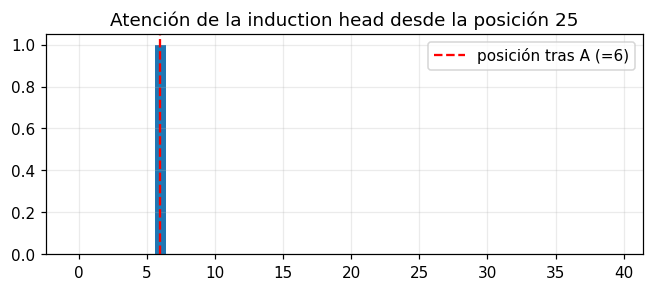

In [25]:
# ---- Induction head construida a mano ----
rng = np.random.default_rng(5); Vv_, T_, d_ = 64, 40, 128
emb = rng.normal(size=(Vv_, d_)); emb /= np.linalg.norm(emb, axis=1, keepdims=True)
def induction_predict(tokens, t, sharp=30.0):
    X = emb[tokens]; prev = np.zeros_like(X); prev[1:] = X[:-1]          # capa 1: previous-token head
    sc = (X[t] @ prev.T) * sharp; sc[t + 1:] = -1e9; sc[0] = -1e9        # capa 2: QK (query=token actual, key=token previo de j) + causalidad
    w = softmax_np(sc); return int(((w @ X) @ emb.T).argmax()), w        # OV: copia el token en j
ok = 0; N = 300
for s in range(N):
    r = np.random.default_rng(100 + s); tk = r.permutation(Vv_)[:T_].copy(); i, j = r.integers(1, 15), r.integers(20, T_ - 1); tk[j] = tk[i]
    ok += (induction_predict(tk, j)[0] == tk[i + 1])
print(f"precisión de la induction head: {ok/N:.3f} sobre {N} secuencias")
tk = np.random.default_rng(100).permutation(Vv_)[:T_].copy(); tk[25] = tk[5]; _, w = induction_predict(tk, 25)
plt.figure(figsize=(7, 2.6)); plt.bar(range(T_), w); plt.axvline(6, color="r", ls="--", label="posición tras A (=6)"); plt.title("Atención de la induction head desde la posición 25"); plt.legend(); plt.show()

In [26]:
# ---- Verificación de la factorización QK/OV y de la simetría de gauge ----
d, h, dk, n = 32, 4, 8, 10
X = tf.random.normal((n, d)); WQ, WK, WV = [tf.random.normal((h, d, dk)) / math.sqrt(d) for _ in range(3)]; WO = tf.random.normal((h, dk, d)) / math.sqrt(dk)
heads = [tf.nn.softmax((X @ WQ[i]) @ tf.transpose(X @ WK[i]) / math.sqrt(dk)) @ (X @ WV[i]) for i in range(h)]
out_concat = tf.concat(heads, -1) @ tf.reshape(WO, (h * dk, d))
out_sum = tf.add_n([tf.nn.softmax((X @ WQ[i]) @ tf.transpose(X @ WK[i]) / math.sqrt(dk)) @ X @ (WV[i] @ WO[i]) for i in range(h)])
print(f"||concat(heads)·W^O − Σ_h A_h X W_OV,h|| = {tf.norm(out_concat - out_sum).numpy():.2e}   (≈ 0: cabezas aditivas e independientes)")
R = tf.random.normal((dk, dk)) + 3 * tf.eye(dk); Rinv = tf.linalg.inv(R)
s1 = (X @ WQ[0]) @ tf.transpose(X @ WK[0]); s2 = (X @ (WQ[0] @ R)) @ tf.transpose(X @ (WK[0] @ tf.transpose(Rinv)))
print(f"invariancia de gauge (Q→QR, K→KR^-T): ||S − S'|| = {tf.norm(s1 - s2).numpy():.2e}")

||concat(heads)·W^O − Σ_h A_h X W_OV,h|| = 3.38e-06   (≈ 0: cabezas aditivas e independientes)
invariancia de gauge (Q→QR, K→KR^-T): ||S − S'|| = 1.46e-05


In [27]:
# ---- Series de tiempo: naive estacional vs. lineal vs. Transformer con parches (split TEMPORAL, sin barajar entre train y test) ----
rng = np.random.default_rng(0); T = 4000; t = np.arange(T)
series = (0.002 * t + 2 * np.sin(2 * np.pi * t / 24) + 1.0 * np.sin(2 * np.pi * t / 168) + 0.4 * rng.normal(size=T)).astype("float32")
L, H, P = 96, 24, 8
def windows(s, L, H, stride=2):
    idx = range(0, len(s) - L - H, stride); return np.stack([s[i:i + L] for i in idx]), np.stack([s[i + L:i + L + H] for i in idx])
cut = int(0.7 * T); Xtr, Ytr = windows(series[:cut], L, H); Xte, Yte = windows(series[cut:], L, H)
def revin(x): m = x.mean(1, keepdims=True); return x - m, m
mse_naive = np.mean((np.tile(Xte[:, -24:], (1, H // 24)) - Yte) ** 2)
xl, ml = revin(Xtr); xl_te, ml_te = revin(Xte)
lin = keras.Sequential([keras.Input((L,)), layers.Dense(H)]); lin.compile(keras.optimizers.Adam(1e-3), "mse"); lin.fit(xl, Ytr - ml, epochs=8, batch_size=64, verbose=0)
mse_lin = np.mean((lin.predict(xl_te, verbose=0) + ml_te - Yte) ** 2)
def build_patch(L, P, H, d=64, nl=2):
    npatch = L // P; inp = keras.Input((L,)); h = layers.Reshape((npatch, P))(inp); h = layers.Dense(d)(h) + layers.Embedding(npatch, d)(tf.range(npatch))[None]
    for _ in range(nl): h = TransformerBlock(d, 4, 2 * d, pre_ln=True, dropout=0.1)(h)
    return keras.Model(inp, layers.Dense(H)(layers.Flatten()(h)))
pt = build_patch(L, P, H); pt.compile(keras.optimizers.Adam(1e-3), "mse"); pt.fit(xl, Ytr - ml, epochs=8, batch_size=64, verbose=0, validation_split=0.1)
mse_pt = np.mean((pt.predict(xl_te, verbose=0) + ml_te - Yte) ** 2)
print(f"MSE de prueba (horizonte {H}): naive estacional = {mse_naive:.4f} | lineal = {mse_lin:.4f} | Transformer con parches = {mse_pt:.4f}")
print("(ruido irreducible ≈ 0.16). REPORTE el ranking que obtenga: la lección es comparar con líneas base fuertes.")

/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_48', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_49', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


MSE de prueba (horizonte 24): naive estacional = 0.7134 | lineal = 0.4400 | Transformer con parches = 0.2372
(ruido irreducible ≈ 0.16). REPORTE el ranking que obtenga: la lección es comparar con líneas base fuertes.


In [28]:
# ---- FT-Transformer (tabulares) frente a Gradient Boosting ----
class FTTransformer(keras.Model):
    def __init__(self, n_num, cat_cards, d=32, n_heads=4, n_layers=2, n_out=1):
        super().__init__()
        self.num_w = self.add_weight(shape=(n_num, d), initializer="glorot_uniform", name="num_w"); self.num_b = self.add_weight(shape=(n_num, d), initializer="zeros", name="num_b")
        self.cat_emb = [layers.Embedding(c, d) for c in cat_cards]; self.cls = self.add_weight(shape=(1, 1, d), initializer="glorot_uniform", name="cls")
        self.blocks = [TransformerBlock(d, n_heads, 2 * d, pre_ln=True, dropout=0.1) for _ in range(n_layers)]; self.ln, self.head = layers.LayerNormalization(), layers.Dense(n_out)
    def call(self, inputs, training=False):
        xn, xc = inputs
        toks = [xn[:, :, None] * self.num_w[None] + self.num_b[None]] + [e(xc[:, i])[:, None, :] for i, e in enumerate(self.cat_emb)]
        h = tf.concat([tf.tile(self.cls, (tf.shape(xn)[0], 1, 1))] + toks, axis=1)
        for b in self.blocks: h = b(h, training=training)
        return self.head(self.ln(h[:, 0]))
rng = np.random.default_rng(0); N = 6000
xn = rng.normal(size=(N, 5)).astype("float32"); xc = rng.integers(0, 4, size=(N, 2)).astype("int32")
y = (np.sin(xn[:, 0]) + xn[:, 1] * (xc[:, 0] == 2) + 0.5 * xn[:, 2] ** 2 + 0.2 * rng.normal(size=N)).astype("float32")
tr, te = slice(0, 5000), slice(5000, N)
ft = FTTransformer(5, [4, 4]); ft.compile(keras.optimizers.AdamW(1e-3, weight_decay=1e-4), "mse"); ft.fit((xn[tr], xc[tr]), y[tr], epochs=10, batch_size=128, verbose=0)
from sklearn.ensemble import GradientBoostingRegressor
X_gb = np.hstack([xn, xc]); gb = GradientBoostingRegressor(random_state=0).fit(X_gb[tr], y[tr])
print(f"MSE prueba: FT-Transformer = {np.mean((ft.predict((xn[te], xc[te]), verbose=0)[:, 0] - y[te])**2):.4f} | Gradient Boosting = {np.mean((gb.predict(X_gb[te]) - y[te])**2):.4f}")
print("REPORTE ambos números: los árboles suelen ser una línea base muy fuerte en tabulares; compare siempre.")

/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_50', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/lihkir/miniconda3/envs/Kalba/lib/python3.10/site-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'transformer_block_51', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


MSE prueba: FT-Transformer = 0.1053 | Gradient Boosting = 0.0721
REPORTE ambos números: los árboles suelen ser una línea base muy fuerte en tabulares; compare siempre.



## **K. Mapa de frontera**


### **K.1 Mixture of Experts (MoE)**
Reemplazar la FFN densa por $E$ expertos y un **enrutador** que activa sólo los $k$ mejores por token:
$$y=\sum_{e\in\text{Top-}k(g(x))}\operatorname{softmax}(g(x))_e\,\mathrm{FFN}_e(x),\qquad g(x)=W_rx.$$
Los parámetros **totales** crecen con $E$ y el cómputo **activo** sólo con $k$. *Switch Transformer* [49] usa $k=1$ y una **pérdida auxiliar de balance de carga** $\mathcal{L}_{aux}=E\sum_ef_eP_e$ ($f_e$: fracción de tokens enrutados a $e$; $P_e$: probabilidad media del enrutador). *Mixtral 8×7B* [50]: $E=8$, $k=2$.

### **K.2 Vision Transformer (ViT) y multimodal**
**ViT** [51]: dividir la imagen en parches, aplanarlos, proyectarlos linealmente y tratarlos como *tokens* (+ posición + `[CLS]`). Con poco dato las CNN generalizan mejor (sesgo inductivo de localidad); con **mucho** dato ViT las iguala o supera. **CLIP** [52]: dos codificadores con pérdida **contrastiva simétrica** (InfoNCE) sobre un lote de $B$ pares:
$$\mathcal{L}=-\frac1{2B}\sum_{i=1}^{B}\Big[\log\frac{e^{s_{ii}/\tau}}{\sum_je^{s_{ij}/\tau}}+\log\frac{e^{s_{ii}/\tau}}{\sum_je^{s_{ji}/\tau}}\Big],\quad s_{ij}=\langle f(I_i),g(T_j)\rangle.$$

### **K.3 LoRA y QLoRA**
**LoRA** [53]: congelar $W_0\in\mathbb{R}^{d\times k}$ y entrenar una actualización de **rango bajo** $W=W_0+\tfrac{\alpha}{r}BA$, con $B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r\ll\min(d,k)$ y $B=0$ al inicio. Parámetros entrenables: $r(d+k)$ en vez de $dk$. Hipótesis subyacente: **baja dimensión intrínseca** del ajuste fino [54]. **QLoRA** [55] cuantiza $W_0$ a 4 bits (*NormalFloat*) y entrena adaptadores LoRA en 16 bits.

### **K.4 Alineación: RLHF y DPO**
**RLHF** [56, 57]: (1) ajuste supervisado; (2) **modelo de recompensa** con Bradley–Terry, $P(y_w\succ y_l)=\sigma(r(x,y_w)-r(x,y_l))$; (3) optimizar la política con RL (PPO) bajo penalización KL:
$$\max_\pi\ \mathbb{E}_{x,\,y\sim\pi}[r(x,y)]-\beta\,D_{KL}\big(\pi(\cdot|x)\,\|\,\pi_{ref}(\cdot|x)\big).$$
**DPO** [58]: el óptimo de ese problema es $\pi^\star\propto\pi_{ref}e^{r/\beta}$, de donde $r=\beta\log(\pi/\pi_{ref})+\text{cte}(x)$ y se **elimina el modelo de recompensa y el RL**:
$$\mathcal{L}_{DPO}=-\mathbb{E}\Big[\log\sigma\Big(\beta\log\tfrac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)}-\beta\log\tfrac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\Big)\Big].$$
*(Conecta con el curso de VAE: optimización con penalización KL.)*

### **K.5 Modelos de espacio de estados (S4, Mamba)**
Un **SSM** lineal e invariante en el tiempo es $h'(t)=Ah(t)+Bx(t),\ y(t)=Ch(t)$; discretizado, $h_t=\bar Ah_{t-1}+\bar Bx_t$. Se evalúa como **recurrencia** (inferencia $O(1)$ por token) o como **convolución** (entrenamiento paralelo). **S4** [59] parametriza $A$ con estructura (HiPPO + NPLR). **Mamba** [60] hace los parámetros **dependientes de la entrada** (selectividad) con un *scan* paralelo consciente del hardware. **Mamba-2** [61] establece la **dualidad** SSM–atención. *Debate abierto:* los híbridos (Transformer + SSM) suelen superar a ambos puros; los SSM puros tienen dificultad en tareas de **recuperación exacta** (*copy*, *associative recall*), que la atención resuelve de forma natural (Bloque I).

In [29]:
# ---- K.1: capa MoE top-k con pérdida de balance de carga ----
class MoE(layers.Layer):
    def __init__(self, d, d_ff, n_exp=4, k=1, **kw):
        super().__init__(**kw); self.E, self.k = n_exp, k; self.router = layers.Dense(n_exp, use_bias=False)
        self.experts = [keras.Sequential([layers.Dense(d_ff, activation="gelu"), layers.Dense(d)]) for _ in range(n_exp)]
    def call(self, x):
        probs = tf.nn.softmax(self.router(x), -1); topv, topi = tf.math.top_k(probs, self.k); gate = topv / tf.reduce_sum(topv, -1, keepdims=True)
        outs = tf.stack([e(x) for e in self.experts], -2)                       # versión densa (didáctica)
        sel = tf.reduce_sum(tf.one_hot(topi, self.E) * gate[..., None], -2); y = tf.reduce_sum(sel[..., None] * outs, -2)
        f = tf.reduce_mean(tf.reduce_sum(tf.one_hot(topi, self.E), -2), axis=[0, 1]) / self.k; P = tf.reduce_mean(probs, axis=[0, 1])
        self.add_loss(0.01 * self.E * tf.reduce_sum(f * P)); return y
moe = MoE(32, 64, n_exp=4, k=2); y = moe(tf.random.normal((2, 10, 32)))
print("salida MoE:", y.shape, "| pérdida auxiliar:", float(tf.add_n(moe.losses)), "| parámetros totales:", moe.count_params())

# ---- K.3: LoRA ----
class LoRADense(layers.Layer):
    def __init__(self, base, r=4, alpha=8, **kw): super().__init__(**kw); self.base, self.r, self.alpha = base, r, alpha; base.trainable = False
    def build(self, input_shape):
        self.A = self.add_weight(shape=(input_shape[-1], self.r), initializer="he_uniform", name="A"); self.B = self.add_weight(shape=(self.r, self.base.units), initializer="zeros", name="B")
    def call(self, x): return self.base(x) + (self.alpha / self.r) * (x @ self.A) @ self.B
base = layers.Dense(256); x = tf.random.normal((3, 128)); _ = base(x); lora = LoRADense(base, r=4)
print("LoRA con B=0 reproduce la capa base:", np.allclose(lora(x).numpy(), base(x).numpy(), atol=1e-6))
tr_p = sum(int(np.prod(v.shape)) for v in lora.trainable_variables); full = 128 * 256 + 256; print(f"entrenables LoRA = {tr_p} frente a {full} del ajuste completo ({100*tr_p/full:.1f} %)")

# ---- K.4: pérdida DPO ----
def dpo_loss(lp_w, lp_l, ref_w, ref_l, beta=0.1):
    margin = beta * ((lp_w - ref_w) - (lp_l - ref_l)); return -tf.reduce_mean(tf.math.log_sigmoid(margin)), margin
lw, ll, rw, rl = [tf.constant(v) for v in ([-10., -12., -9.], [-11., -11.5, -12.], [-10.5, -11.5, -10.], [-10.5, -11.5, -11.])]
loss, margin = dpo_loss(lw, ll, rw, rl); print("DPO: pérdida =", float(loss), "| márgenes implícitos =", margin.numpy().round(3))

salida MoE: (2, 10, 32) | pérdida auxiliar: 0.010492553934454918 | parámetros totales: 16896
LoRA con B=0 reproduce la capa base: True
entrenables LoRA = 1536 frente a 33024 del ajuste completo (4.7 %)
DPO: pérdida = 0.6536650657653809 | márgenes implícitos = [ 0.1  -0.05  0.2 ]


In [30]:
# ---- K.5: SSM lineal: equivalencia recurrencia <-> convolución ----
rng = np.random.default_rng(0); N, T = 8, 64
A = -np.diag(rng.uniform(0.1, 1.0, N)); Bv = rng.normal(size=(N, 1)); Cv = rng.normal(size=(1, N)); dt = 0.1
Abar = np.diag(np.exp(np.diag(A) * dt)); Bbar = np.linalg.solve(A, (Abar - np.eye(N))) @ Bv        # discretización ZOH
x = rng.normal(size=T); h = np.zeros((N, 1)); y_rec = []
for t in range(T): h = Abar @ h + Bbar * x[t]; y_rec.append(float(Cv @ h))
Kc = np.array([float(Cv @ np.linalg.matrix_power(Abar, k) @ Bbar) for k in range(T)])
y_conv = np.array([np.sum(Kc[:t + 1][::-1] * x[:t + 1]) for t in range(T)])
print(f"máx |recurrente − convolución| = {np.max(np.abs(np.array(y_rec) - y_conv)):.2e}   (≈ 0)")

máx |recurrente − convolución| = 2.78e-16   (≈ 0)


/tmp/ipykernel_372268/3815982007.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  for t in range(T): h = Abar @ h + Bbar * x[t]; y_rec.append(float(Cv @ h))
/tmp/ipykernel_372268/3815982007.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Kc = np.array([float(Cv @ np.linalg.matrix_power(Abar, k) @ Bbar) for k in range(T)])



## **Ejercicios propuestos**
**Teóricos**
1. **(T1)** Demuestre que *multi-head attention* y la FFN por token son equivariantes a permutaciones. ¿Qué falla con una máscara de ventana local simétrica? ¿Y con una causal?
2. **(T2)** Si $q_i$ y $k_i$ tienen correlación $\rho$, calcule $\operatorname{Var}(q^\top k)$ y proponga el escalado correcto.
3. **(T3)** Construya un ejemplo con $n=3,\ d_k=1$ de una matriz estocástica que **no** pueda representarse exactamente como $\operatorname{softmax}(S)$.
4. **(T4)** Demuestre que ALiBi es una codificación relativa pura. ¿Por qué extrapola mejor que sumar sinusoides?
5. **(T5)** Pruebe que si $A$ es estocástica por filas y positiva entonces $\operatorname{res}(AX)<\operatorname{res}(X)$ salvo que $X$ ya tenga filas idénticas.
6. **(T6)** Calcule a primer orden en $\|F'\|\ll1$ el jacobiano de un bloque Pre-LN y de uno Post-LN y compare $\|\partial x_L/\partial x_0\|$.
7. **(T7)** Demuestre que la complejidad de IO de FlashAttention es $\Theta(n^2d^2/M)$ para $M\ge d^2$ y compárela con la estándar.
8. **(T8)** Derive $N^\star,D^\star$ si el coste de **inferencia** de $I$ tokens se suma: $C=6ND+2NI$. ¿Qué cambia respecto a Chinchilla? (Ver [31].)
9. **(T9–T10)** Enuncie con precisión qué *no* implica el Teorema 9 y dé un argumento de por qué PARITY es fácil con chain-of-thought.

**Computacionales (TensorFlow)**
10. Implemente **ALiBi** y compare la extrapolación de longitud con RoPE y sinusoidal en el modelo del Bloque D.
11. Añada **KV-cache** al `TinyGPT` y mida el tiempo de generación frente a recomputar.
12. Repita Pre-LN vs Post-LN con $L\in\{4,8,16,32\}$ **con y sin warm-up** y grafique.
13. Entrene un Transformer en **copia con distractores** y verifique la formación de una **induction head**.
14. Implemente **GQA** con $h_{kv}\in\{1,2,4,8\}$ y mida el trade-off calidad/memoria.
15. En el Bloque J añada **ARIMA/ETS** como línea base con *rolling-origin cross-validation*. ¿Sigue ganando el Transformer?




# **Referencias**

- **[1]** Vaswani, A. et al. (2017). *Attention is all you need*. **NeurIPS 30**. arXiv:1706.03762.
- Bahdanau, D., Cho, K. & Bengio, Y. (2015). *Neural machine translation by jointly learning to align and translate*. **ICLR 2015**. arXiv:1409.0473.
- Luong, M.-T., Pham, H. & Manning, C. D. (2015). *Effective approaches to attention-based neural machine translation*. **EMNLP 2015**. arXiv:1508.04025.
- **[2]** Lee, J. et al. (2019). *Set Transformer*. **ICML 2019**. arXiv:1810.00825.
- **[8]** Devlin, J. et al. (2019). *BERT*. **NAACL 2019**. arXiv:1810.04805.
- Raffel, C. et al. (2020). *Exploring the limits of transfer learning with a unified text-to-text transformer* (T5). **JMLR**, 21(140). arXiv:1910.10683.
- Ranzato, M. et al. (2016). *Sequence level training with recurrent neural networks*. **ICLR 2016**. arXiv:1511.06732.
- **[3]** Yun, C., Bhojanapalli, S., Rawat, A. S., Reddi, S. J. & Kumar, S. (2020). *Are transformers universal approximators of sequence-to-sequence functions?* **ICLR 2020**. arXiv:1912.10077.
- **[4]** Haviv, A., Ram, O., Press, O., Izsak, P. & Levy, O. (2022). *Transformer language models without positional encodings still learn positional information*. **Findings of EMNLP 2022**. arXiv:2203.16634.
- **[5]** Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning*. MIT Press.
- **[6]** Dehghani, M. et al. (2023). *Scaling vision transformers to 22 billion parameters*. **ICML 2023**. arXiv:2302.05442.
- **[7]** Bhojanapalli, S., Yun, C., Rawat, A. S., Reddi, S. & Kumar, S. (2020). *Low-rank bottleneck in multi-head attention models*. **ICML 2020**, PMLR 119.
- **[9]** Shaw, P., Uszkoreit, J. & Vaswani, A. (2018). *Self-attention with relative position representations*. **NAACL 2018**.
- **[10]** Su, J. et al. (2021). *RoFormer: Enhanced transformer with rotary position embedding*. arXiv:2104.09864.
- **[11]** Press, O., Smith, N. A. & Lewis, M. (2022). *Train short, test long: Attention with linear biases enables input length extrapolation*. **ICLR 2022**. arXiv:2108.12409.
- **[12]** Barbero, F. et al. (2025). *Round and round we go! What makes rotary positional encodings useful?* **ICLR 2025**. arXiv:2410.06205.
- **[13]** Ainslie, J. et al. (2023). *GQA: Training generalized multi-query transformer models from multi-head checkpoints*. **EMNLP 2023**. arXiv:2305.13245.
- **[14]** Dong, Y., Cordonnier, J.-B. & Loukas, A. (2021). *Attention is not all you need: Pure attention loses rank doubly exponentially with depth*. **ICML 2021**. arXiv:2103.03404.
- **[15]** Noci, L. et al. (2022). *Signal propagation in transformers: Theoretical perspectives and the role of rank collapse*. **NeurIPS 2022**.
- **[16]** Xiong, R. et al. (2020). *On layer normalization in the transformer architecture*. **ICML 2020**. arXiv:2002.04745.
- **[17]** Liu, L., Liu, X., Gao, J., Chen, W. & Han, J. (2020). *Understanding the difficulty of training transformers*. **EMNLP 2020**. arXiv:2004.08249.
- **[18]** Wang, H. et al. (2024). *DeepNet: Scaling transformers to 1,000 layers*. **IEEE TPAMI**. arXiv:2203.00555.
- **[19]** Dao, T., Fu, D. Y., Ermon, S., Rudra, A. & Ré, C. (2022). *FlashAttention: Fast and memory-efficient exact attention with IO-awareness*. **NeurIPS 2022**. arXiv:2205.14135.
- **[20]** Milakov, M. & Gimelshein, N. (2018). *Online normalizer calculation for softmax*. arXiv:1805.02867.
- **[21]** Rabe, M. N. & Staats, C. (2021). *Self-attention does not need $O(n^2)$ memory*. arXiv:2112.05682.
- **[22]** Dao, T. (2023). *FlashAttention-2*. arXiv:2307.08691.
- **[23]** Wang, S. et al. (2020). *Linformer*. arXiv:2006.04768.
- **[24]** Choromanski, K. et al. (2021). *Rethinking attention with Performers*. **ICLR 2021**. arXiv:2009.14794.
- **[25]** Katharopulos, A. et al. (2020). *Transformers are RNNs*. **ICML 2020**. arXiv:2006.16236.
- **[26]** Shazeer, N. (2019). *Fast transformer decoding: One write-head is all you need*. arXiv:1911.02150.
- **[27]** Kaplan, J. et al. (2020). *Scaling laws for neural language models*. arXiv:2001.08361.
- **[28]** Hoffmann, J. et al. (2022). *Training compute-optimal large language models*. arXiv:2203.15556.
- **[29]** Besiroglu, T. et al. (2024). *Chinchilla scaling: A replication attempt*. arXiv:2404.10102.
- **[30]** Muennighoff, N. et al. (2023). *Scaling data-constrained language models*. **NeurIPS 2023**. arXiv:2305.16264.
- **[31]** Sardana, N. et al. (2024). *Beyond Chinchilla-optimal: Accounting for inference in language model scaling laws*. **ICML 2024**. arXiv:2401.00448.
- **[32]** Edelman, B. L., Goel, S., Kakade, S. & Zhang, C. (2022). *Inductive biases and variable creation in self-attention mechanisms*. **ICML 2022**. arXiv:2110.10090.
- **[33]** Jiang, H. & Li, Q. (2024). *Approximation rate of the transformer architecture for sequence modeling*. **NeurIPS 2024**. arXiv:2305.18475.
- **[34]** Hahn, M. (2020). *Theoretical limitations of self-attention in neural sequence models*. **TACL**, 8, 156–171.
- **[35]** Merrill, W. & Sabharwal, A. (2023). *The parallelism tradeoff: Limitations of log-precision transformers*. **TACL**, 11, 531–545.
- **[36]** Chiang, D. & Cholak, P. (2022). *Overcoming a theoretical limitation of self-attention*. **ACL 2022**.
- **[37]** Merrill, W. & Sabharwal, A. (2023). *A logic for expressing log-precision transformers*. **NeurIPS 2023**. arXiv:2210.02671.
- **[38]** Merrill, W. & Sabharwal, A. (2024). *The expressive power of transformers with chain of thought*. **ICLR 2024**. arXiv:2310.07923.
- **[39]** Li, Z., Liu, H., Zhou, D. & Ma, T. (2024). *Chain of thought empowers transformers to solve inherently serial problems*. **ICLR 2024**. arXiv:2402.12875.
- **[40]** Strobl, L., Merrill, W., Weiss, G., Chiang, D. & Angluin, D. (2024). *What formal languages can transformers express? A survey*. **TACL**, 12. arXiv:2311.00208.
- **[41]** Elhage, N. et al. (2021). *A mathematical framework for transformer circuits*. Transformer Circuits Thread (Anthropic). https://transformer-circuits.pub/2021/framework/index.html
- **[42]** Olsson, C. et al. (2022). *In-context learning and induction heads*. Transformer Circuits Thread. arXiv:2209.11895.
- **[43]** Zeng, A., Chen, M., Zhang, L. & Xu, Q. (2023). *Are transformers effective for time series forecasting?* **AAAI 2023**. arXiv:2205.13504.
- **[44]** Nie, Y., Nguyen, N. H., Sinthong, P. & Kalagnanam, J. (2023). *A time series is worth 64 words: Long-term forecasting with transformers* (PatchTST). **ICLR 2023**. arXiv:2211.14730.
- **[45]** Ansari, A. F. et al. (2024). *Chronos: Learning the language of time series*. arXiv:2403.07815.
- **[46]** Gorishniy, Y., Rubachev, I., Khrulkov, V. & Babenko, A. (2021). *Revisiting deep learning models for tabular data*. **NeurIPS 2021**. arXiv:2106.11959.
- **[47]** Grinsztajn, L., Oyallon, E. & Varoquaux, G. (2022). *Why do tree-based models still outperform deep learning on typical tabular data?* **NeurIPS 2022 (Datasets and Benchmarks)**. arXiv:2207.08815.
- **[48]** Shwartz-Ziv, R. & Armon, A. (2022). *Tabular data: Deep learning is not all you need*. **Information Fusion**, 81. arXiv:2106.03253.
- **[49]** Fedus, W., Zoph, B. & Shazeer, N. (2022). *Switch transformers*. **JMLR**, 23(120). arXiv:2101.03961.
- **[50]** Jiang, A. Q. et al. (2024). *Mixtral of experts*. arXiv:2401.04088.
- **[51]** Dosovitskiy, A. et al. (2021). *An image is worth 16×16 words*. **ICLR 2021**. arXiv:2010.11929.
- **[52]** Radford, A. et al. (2021). *Learning transferable visual models from natural language supervision* (CLIP). **ICML 2021**. arXiv:2103.00020.
- **[53]** Hu, E. J. et al. (2022). *LoRA: Low-rank adaptation of large language models*. **ICLR 2022**. arXiv:2106.09685.
- **[54]** Aghajanyan, A., Gupta, S. & Zettlemoyer, L. (2021). *Intrinsic dimensionality explains the effectiveness of language model fine-tuning*. **ACL 2021**. arXiv:2012.13255.
- **[55]** Dettmers, T., Pagnoni, A., Holtzman, A. & Zettlemoyer, L. (2023). *QLoRA: Efficient finetuning of quantized LLMs*. **NeurIPS 2023**. arXiv:2305.14314.
- **[56]** Christiano, P. et al. (2017). *Deep reinforcement learning from human preferences*. **NeurIPS 2017**. arXiv:1706.03741.
- **[57]** Ouyang, L. et al. (2022). *Training language models to follow instructions with human feedback*. **NeurIPS 2022**. arXiv:2203.02155.
- **[58]** Rafailov, R. et al. (2023). *Direct preference optimization*. **NeurIPS 2023**. arXiv:2305.18290.
- **[59]** Gu, A., Goel, K. & Ré, C. (2022). *Efficiently modeling long sequences with structured state spaces* (S4). **ICLR 2022**. arXiv:2111.00396.
- **[60]** Gu, A. & Dao, T. (2023). *Mamba: Linear-time sequence modeling with selective state spaces*. arXiv:2312.00752.
- **[61]** Dao, T. & Gu, A. (2024). *Transformers are SSMs*. **ICML 2024**. arXiv:2405.21060.
- Jurafsky, D. & Martin, J. H. (2025). *Speech and Language Processing*, 3.ª ed. (borrador). https://web.stanford.edu/~jurafsky/slp3/
- Prince, S. J. D. (2023). *Understanding Deep Learning*. MIT Press. https://udlbook.github.io/udlbook/ (Cap. 12)
- Bishop, C. M. & Bishop, H. (2024). *Deep Learning: Foundations and Concepts*. Springer. (Cap. 12)
- Murphy, K. P. (2023). *Probabilistic Machine Learning: Advanced Topics*. MIT Press.
- Tay, Y. et al. (2022). *Efficient transformers: A survey*. **ACM Computing Surveys**, 55(6). arXiv:2009.06732.
- Stanford CS336 *Language Modeling from Scratch* y CS224N *NLP with Deep Learning* (materiales abiertos).